# Joint Digital Transformation and the Middle-Income Trap
## Empirical notebook — baseline framework (equations.pdf)

This notebook takes the panel built by `data_acquisition_colab_fixed.ipynb`
(`/content/data/processed/panel.parquet`) and estimates the empirical framework
of the paper. Each section shows the **equation from the paper**, how it maps to
the **collected data**, the estimation code, and a short interpretation.

**Data → theory mapping**

| Theory symbol | Meaning | Panel variable(s) |
|---|---|---|
| $g_{it}$ | Real GDP per capita growth | `gdp_pc_growth` |
| $F_{it}$ | FinTech penetration index (Eq. 25) | `findex_account_t_d` (z-scored; see note) |
| $G_{it}$ | AI penetration index (Eq. 27) | `gari_total_2024`, `aipi_*`, `ai_pubs_log` |
| $I_{it}$ | Institutional quality | `wgi_ge` (Government Effectiveness) |
| $H_{it}$ | Human capital | `human_capital_pwt` (PWT, carried fwd past 2019) |
| $\sigma^{KIS}_{it}$ | Knowledge-intensive services share | `kis_share` |
| $\rho_{it}$ | AI-exposed employment share | `rho_exposed_top2` (ILO WP140, income-group level) |
| $MI_{it}$ | Middle-income indicator | `mi_status_hist` |
| $X_{it}$ | Macro controls | `log_gdp, trade_pct_gdp, inflation, investment_pct_gdp, pop_growth, credit_to_private_pct_gdp, secondary_enrollment` |

**Two honest data caveats, stated once here:**
1. *F-index*: Eq. 25 averages four Findex components ($Z_{DP}, Z_{MA}, Z_{MP}, Z_{DA}$).
   Only account ownership is currently mapped in the panel, so $F$ = z-score of
   account ownership — a one-component proxy. Findex is observed only in wave
   years (2011/14/17/21/24); $F$ is linearly interpolated within country between
   waves (a wave-years-only robustness sample is provided).
2. *G-index*: the Readiness (GARI) and Adoption (AIPI) pillars are single-year
   snapshots — cross-sectional variation only. The Activity pillar (OpenAlex
   publications) supplies the within-country time variation.

## 0. Setup and data load

In [ ]:
!pip install -q linearmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda v: f"{v:0.4f}")

CANDIDATES = [
    Path("/content/data/processed/panel.parquet"),
    Path("/content/data/processed/panel.csv"),
    Path("/content/final_panel.csv"),
    Path("panel.parquet"), Path("panel.csv"),
]
panel = None
for p in CANDIDATES:
    if p.exists():
        panel = pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)
        print(f"Loaded {p}: {panel.shape[0]:,} rows x {panel.shape[1]} cols")
        break
if panel is None:
    try:
        from google.colab import files as colab_files
        print("Panel file not found — upload panel.parquet / final_panel.csv now:")
        up = colab_files.upload()
        name = list(up.keys())[0]
        Path(name).write_bytes(up[name])
        panel = (pd.read_parquet(name) if name.endswith(".parquet")
                 else pd.read_csv(name))
        print(f"Loaded upload {name}: {panel.shape}")
    except ImportError:
        raise FileNotFoundError("Run the data-acquisition notebook first, or place "
                                "panel.parquet next to this notebook.")

panel = panel.sort_values(["iso3", "year"]).reset_index(drop=True)
print("Columns:", list(panel.columns))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 5.9 MB/s eta 0:00:00
Panel file not found — upload panel.parquet / final_panel.csv now:


Saving final_panel (12).csv to final_panel (12).csv
Loaded upload final_panel (12).csv: (3474, 42)
Columns: ['iso3', 'year', 'gdp_pc_growth', 'gdp_pc_ppp', 'trade_pct_gdp', 'inflation', 'investment_pct_gdp', 'pop_growth', 'credit_to_private_pct_gdp', 'secondary_enrollment', 'tertiary_enrollment', 'human_capital_pwt', 'ai_pubs_count', 'kis_share', 'wgi_cc', 'wgi_ge', 'wgi_pv', 'wgi_rl', 'wgi_rq', 'wgi_va', 'findex_account_t_d', 'gini_disp', 'gini_mkt', 'income_group', 'mi_status', 'hi_status', 'gari_total_2024', 'aipi_total', 'aipi_digital_infra', 'aipi_human_capital', 'aipi_innovation', 'aipi_regulation', 'gini_disp_hist', 'income_group_hist', 'mi_status_hist', 'hi_status_hist', 'rho_gradient4', 'rho_gradient3', 'rho_exposed_top2', 'log_gdp', 'ai_pubs_log', 'G_pillar_activity_starter']


### 0b. Sample hygiene (run before anything else)

Three fixes the raw panel needs before estimation:
1. **Winsorize growth at the 1st/99th percentile** — war/COVID swings in
   Libya (±91pp), Macao (±75pp) etc. would otherwise dominate the FE estimates.
2. **Keep World Bank–classified economies only** (rows with an income group at
   some point) — drops territories/micro-entities outside the theory's scope.
3. **Re-date the 16 late-fielded 2022 Findex observations to the 2021 wave**
   so they join the wave structure instead of dangling.

In [ ]:
# 1) winsorize growth
lo, hi = panel["gdp_pc_growth"].quantile([0.01, 0.99])
n_capped = ((panel["gdp_pc_growth"] < lo) | (panel["gdp_pc_growth"] > hi)).sum()
panel["gdp_pc_growth_raw"] = panel["gdp_pc_growth"]
panel["gdp_pc_growth"] = panel["gdp_pc_growth"].clip(lo, hi)
print(f"growth winsorized at [{lo:.1f}, {hi:.1f}] pp — {n_capped} obs capped")

# 2) WB-classified economies only
classified = (panel.groupby("iso3")
              .apply(lambda d: d[["income_group","income_group_hist"]].notna().any().any()))
keep = set(classified[classified].index)
before = panel["iso3"].nunique()
panel = panel[panel["iso3"].isin(keep)].copy()
print(f"economies: {before} -> {panel['iso3'].nunique()} "
      f"(dropped unclassified territories/entities)")

# 3) fold late-fielded 2022 Findex into the 2021 wave
late = panel.loc[(panel["year"] == 2022) & panel["findex_account_t_d"].notna(),
                 ["iso3", "findex_account_t_d"]]
for _, r in late.iterrows():
    m21 = (panel["iso3"] == r["iso3"]) & (panel["year"] == 2021)
    if m21.any() and panel.loc[m21, "findex_account_t_d"].isna().all():
        panel.loc[m21, "findex_account_t_d"] = r["findex_account_t_d"]
panel.loc[panel["year"] == 2022, "findex_account_t_d"] = np.nan
print(f"re-dated {len(late)} late-fielded Findex observations 2022 -> 2021")
panel = panel.sort_values(["iso3","year"]).reset_index(drop=True)

growth winsorized at [-17.6, 15.7] pp — 64 obs capped
economies: 246 -> 217 (dropped unclassified territories/entities)
re-dated 16 late-fielded Findex observations 2022 -> 2021


### 0c. Principled imputation (Kalman smoother, per country)

**What gets imputed:** `human_capital_pwt` (PWT ends 2019 — a slow-moving stock,
extrapolated at most 5 years with a local-linear-trend state-space model) and
short interior gaps in the WGI/WDI controls. Each imputed value is flagged in a
`*_imp` column.

**What never gets imputed:** Findex between waves (no information exists there
— interpolation in Section 1 is already the honest treatment), SWIID Gini
(itself the output of a Bayesian imputation model), `kis_share` for countries
that never ran the survey (missing-not-at-random), and the dependent variable.

A complete-case comparison of the headline coefficients runs at the end of the
notebook; single imputation slightly understates SEs, so if a referee asks,
the gold-standard upgrade is multiple imputation for TSCS data
(Honaker–King *Amelia*) with Rubin's rules.

In [ ]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

def kalman_fill(s, max_extrap=5, min_obs=6):
    # Local-linear-trend Kalman smoother on one country series.
    # Fills interior gaps and extrapolates at most `max_extrap` steps FORWARD
    # past the last observation; never backcasts before the first observation.
    # Returns (filled_values, imputed_flags) aligned to s.index.
    vals = pd.Series(pd.to_numeric(s, errors="coerce").values, dtype=float)
    flags = pd.Series([False] * len(vals))
    if (not vals.isna().any()) or vals.notna().sum() < min_obs:
        return pd.Series(vals.values, index=s.index), pd.Series(flags.values, index=s.index)
    try:
        r = UnobservedComponents(vals, level="local linear trend").fit(disp=0, maxiter=200)
        sm = pd.Series(r.smoothed_state[0], index=vals.index)
        gap   = vals.isna()
        last  = vals.last_valid_index()
        first = vals.first_valid_index()
        blocked = pd.Series(vals.index > last + max_extrap, index=vals.index)   # cap forward
        blocked = blocked | pd.Series(vals.index < first, index=vals.index)     # no backcast
        ok = gap & ~blocked
        vals[ok] = sm[ok]
        flags = ok
    except Exception as e:
        log_msg = f"kalman_fill failed ({type(e).__name__}: {e}) — series left unimputed"
        try:
            log.warning(log_msg)
        except Exception:
            print("WARNING:", log_msg)
    return pd.Series(vals.values, index=s.index), pd.Series(flags.values, index=s.index)

# NOTE: inflation deliberately EXCLUDED — volatile series are bad Kalman
# targets (the ARG 2010-14 backcast artifact came from imputing inflation).
IMPUTE_COLS = ["human_capital_pwt", "wgi_ge", "trade_pct_gdp",
               "investment_pct_gdp", "credit_to_private_pct_gdp",
               "secondary_enrollment"]
for c in IMPUTE_COLS:
    flags = pd.Series(False, index=panel.index)
    for iso, d in panel.groupby("iso3"):
        f, fl = kalman_fill(d[c])
        panel.loc[d.index, c] = f.values
        flags.loc[d.index] = fl.values
    panel[f"{c}_imp"] = flags.astype(int)
    print(f"{c:30s} imputed {int(flags.sum()):4d} values "
          f"-> coverage {panel[c].notna().mean():.3f}")
panel["imp_any"] = panel[[f"{c}_imp" for c in IMPUTE_COLS]].max(axis=1)

human_capital_pwt              imputed  725 values -> coverage 0.668
wgi_ge                         imputed  412 values -> coverage 0.946
trade_pct_gdp                  imputed   50 values -> coverage 0.843
investment_pct_gdp             imputed   42 values -> coverage 0.807
credit_to_private_pct_gdp      imputed  149 values -> coverage 0.799
secondary_enrollment           imputed  344 values -> coverage 0.768


In [ ]:
# Save cleaned and imputed panel

output_csv = "/content/final_panel_imputed.csv"
panel.to_csv(output_csv, index=False)

print(f"Saved: {output_csv}")
print(panel.shape)

Saved: /content/final_panel_imputed.csv
(3255, 50)


In [ ]:
print(panel.shape)
print([c for c in ["findex_account_t_d","gari_total_2024","ai_pubs_log",
                   "gini_disp","wgi_ge","mi_status_hist"] if c not in panel.columns]
      or "all key source columns present")

(3255, 50)
all key source columns present


In [ ]:
from google.colab import files

panel.to_csv("final_panel_imputed.csv", index=False)
files.download("final_panel_imputed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 1. Index construction — Equations (24), (25), (27)

**Standardization (Eq. 24):**
$$Z_{k,it} = \frac{X_{k,it} - \bar{X}_k}{\sigma_k}$$
each component is z-scored against the global sample mean and SD.

**FinTech index (Eq. 25):**
$$F_{it} = \tfrac{1}{4}\left(Z_{DP,it} + Z_{MA,it} + Z_{MP,it} + Z_{DA,it}\right)$$
with the one-component caveat above, here $F_{it} = Z_{\text{account},it}$.

**AI index (Eq. 27):**
$$G_{it} = \tfrac{1}{3}\left(Z^{Readiness}_{it} + Z^{Activity}_{it} + Z^{Adoption}_{it}\right)$$
- Readiness pillar = $Z$(GARI total 2024)
- Activity pillar = $Z(\log(1+\text{AI publications}))$ — the only time-varying pillar
- Adoption pillar = mean of $Z$(AIPI sub-indices: digital infra, human capital, innovation, regulation)

F coverage: 0.622 | G coverage: 0.786 | F·G coverage: 0.605


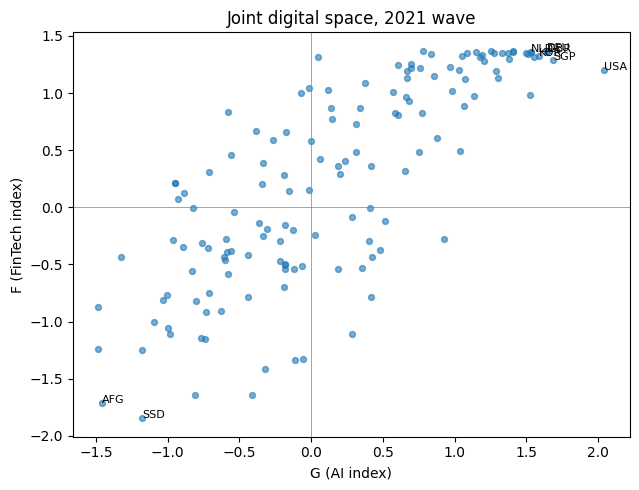

In [ ]:
def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    return (s - s.mean()) / s.std()

# ---- F-index (Eq. 25, one-component version) ----
panel["F_wave"] = zscore(panel["findex_account_t_d"])         # wave years only
# linear interpolation within country between waves (no extrapolation)
panel["F"] = (panel.groupby("iso3")["F_wave"]
                   .transform(lambda s: s.interpolate(limit_area="inside")))

# ---- G-index (Eq. 27) ----
panel["Z_readiness"] = zscore(panel["gari_total_2024"])
panel["Z_activity"]  = zscore(panel["ai_pubs_log"] if "ai_pubs_log" in panel
                              else np.log1p(panel["ai_pubs_count"]))
aipi_subs = [c for c in ["aipi_digital_infra", "aipi_human_capital",
                         "aipi_innovation", "aipi_regulation"] if c in panel.columns]
panel["Z_adoption"] = pd.concat([zscore(panel[c]) for c in aipi_subs], axis=1).mean(axis=1)

panel["G"] = panel[["Z_readiness", "Z_activity", "Z_adoption"]].mean(axis=1, skipna=True)
# require at least 2 of 3 pillars to call it a G observation
panel.loc[panel[["Z_readiness","Z_activity","Z_adoption"]].notna().sum(axis=1) < 2, "G"] = np.nan

panel["FG"] = panel["F"] * panel["G"]

print("F coverage:", f"{panel['F'].notna().mean():.3f}",
      "| G coverage:", f"{panel['G'].notna().mean():.3f}",
      "| F·G coverage:", f"{panel['FG'].notna().mean():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
latest = panel[panel["year"] == 2021].dropna(subset=["F", "G"])
ax.scatter(latest["G"], latest["F"], s=18, alpha=0.6)
for _, r in latest.nlargest(8, "FG").iterrows():
    ax.annotate(r["iso3"], (r["G"], r["F"]), fontsize=8)
ax.set_xlabel("G (AI index)"); ax.set_ylabel("F (FinTech index)")
ax.set_title("Joint digital space, 2021 wave")
ax.axhline(0, lw=0.5, color="grey"); ax.axvline(0, lw=0.5, color="grey")
plt.tight_layout(); plt.show()

## 2. Structural variables — displacement term, Eq. (13)

$$D_{it} = \delta_0 \cdot G_t \cdot \rho_{it} \cdot (1 - H_{it}) \cdot (1 - \sigma^{KIS}_{it})$$

$H$ and $\sigma^{KIS}$ enter as 0–1 *shares*: $H$ is the PWT human-capital index
min-max scaled to [0,1] (carried forward past its 2019 end-date within country);
$\sigma^{KIS}$ = `kis_share`; $\rho$ = `rho_exposed_top2`/100. $\delta_0$ is
absorbed by the regression coefficient, so the regressor is
$G\rho(1-H)(1-\sigma^{KIS})$.

In [ ]:
# H in [0,1]: min-max of PWT human capital, carried forward within country
hc = panel.groupby("iso3")["human_capital_pwt"].ffill()
panel["H"] = (hc - hc.min()) / (hc.max() - hc.min())

panel["sigma_kis"] = pd.to_numeric(panel["kis_share"], errors="coerce")
# kis_share is sparse: fill within country (interpolate inside, then ffill)
panel["sigma_kis"] = (panel.groupby("iso3")["sigma_kis"]
                          .transform(lambda s: s.interpolate(limit_area="inside").ffill()))

panel["rho"] = pd.to_numeric(panel["rho_exposed_top2"], errors="coerce") / 100.0
panel["I"]   = zscore(panel["wgi_ge"])
panel["MI"]  = pd.to_numeric(panel.get("mi_status_hist", panel.get("mi_status")),
                             errors="coerce")

# Displacement regressor (Eq. 13 without delta0)
panel["D_term"] = (panel["G"] * panel["rho"]
                   * (1 - panel["H"]) * (1 - panel["sigma_kis"]))

# interactions used across specs
panel["FI"]  = panel["F"] * panel["I"]
panel["GI"]  = panel["G"] * panel["I"]
panel["GH"]  = panel["G"] * panel["H"]
panel["GS"]  = panel["G"] * panel["sigma_kis"]
panel["FGI"] = panel["FG"] * panel["I"]
panel["F_MI"]  = panel["F"]  * panel["MI"]
panel["G_MI"]  = panel["G"]  * panel["MI"]
panel["FG_MI"] = panel["FG"] * panel["MI"]

CONTROLS = ["log_gdp", "trade_pct_gdp", "inflation", "investment_pct_gdp",
            "pop_growth", "credit_to_private_pct_gdp", "secondary_enrollment"]
CONTROLS = [c for c in CONTROLS if c in panel.columns]

# one-year lags of all regressors (specs use t-1 timing)
LAGVARS = ["F","G","FG","I","FI","GI","GH","GS","FGI","D_term",
           "MI","F_MI","G_MI","FG_MI"] + CONTROLS
for v in LAGVARS:
    panel[f"{v}_l"] = panel.groupby("iso3")[v].shift(1)

print(panel[["F","G","FG","H","sigma_kis","rho","I","MI","D_term"]]
      .describe().T[["count","mean","std","min","max"]])

              count    mean    std     min    max
F         2023.0000  0.0152 0.9732 -2.0324 1.3712
G         2560.0000 -0.0083 0.8668 -1.9196 2.0531
FG        1970.0000  0.6682 0.7721 -0.7264 3.5972
H         2175.0000  0.3595 0.1693  0.0000 1.0000
sigma_kis 2182.0000  0.0660 0.0543  0.0000 0.3083
rho       3210.0000  0.0957 0.0635  0.0110 0.1710
I         3079.0000 -0.0000 1.0000 -2.4222 2.3183
MI        3234.0000  0.4938 0.5000  0.0000 1.0000
D_term    1637.0000  0.0232 0.0440 -0.0817 0.1221


## 3. Estimation machinery

All panel specs are estimated by **fixed-effects OLS** with country fixed effects
$\mu_i$, year fixed effects $\lambda_t$, and standard errors **clustered by
country** (linearmodels `PanelOLS`). Results are collected in `RESULTS` for the
summary table at the end.

In [ ]:
RESULTS = {}

def run_fe(depvar, regressors, df, name, drop_time_invariant=None):
    """PanelOLS with entity+time effects, country-clustered SEs."""
    cols = [depvar] + regressors
    d = df.dropna(subset=cols).copy()
    # time-invariant-within-country regressors are absorbed by entity FE; drop if requested
    if drop_time_invariant:
        regressors = [r for r in regressors if r not in drop_time_invariant]
    d = d.set_index(["iso3", "year"])
    formula = f"{depvar} ~ 1 + " + " + ".join(regressors) + " + EntityEffects + TimeEffects"
    res = PanelOLS.from_formula(formula, data=d, drop_absorbed=True).fit(
        cov_type="clustered", cluster_entity=True)
    RESULTS[name] = res
    print(f"\n===== {name} =====  N={res.nobs:,}  countries={d.index.get_level_values(0).nunique()}")
    tab = pd.DataFrame({"coef": res.params, "se": res.std_errors,
                        "t": res.tstats, "p": res.pvalues})
    print(tab.round(4).to_string())
    return res

def star(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""


## 4. Spec 1 — Baseline joint digital (Eq. 30)

$$g_{it} = \alpha + \beta_1 F_{it-1} + \beta_2 G_{it-1} + \beta_3 (F\times G)_{it-1}
+ \Gamma' X_{it-1} + \mu_i + \lambda_t + \varepsilon_{it}$$

**Hypothesis: $\beta_3 > 0$** — FinTech and AI are productivity complements:
the growth payoff of AI is larger where digital finance is deeper, and vice versa.

In [ ]:
spec1 = run_fe("gdp_pc_growth",
               ["F_l", "G_l", "FG_l"] + [f"{c}_l" for c in CONTROLS],
               panel, "Spec 1 (Eq.30)")
b3, p3 = spec1.params.get("FG_l", np.nan), spec1.pvalues.get("FG_l", np.nan)
print(f"\nbeta3 (F x G) = {b3:.4f}{star(p3)}  ->  hypothesis beta3>0: "
      f"{'SUPPORTED' if (b3 > 0 and p3 < .10) else 'not significant' if b3 > 0 else 'CONTRADICTED'}")


===== Spec 1 (Eq.30) =====  N=1,380  countries=135
                                coef      se       t      p
Intercept                   130.5975 17.9839  7.2619 0.0000
F_l                           1.0783  0.5615  1.9203 0.0551
G_l                           2.2086  2.5763  0.8573 0.3915
FG_l                          1.0956  0.5231  2.0944 0.0364
log_gdp_l                   -13.9566  1.9428 -7.1839 0.0000
trade_pct_gdp_l               0.0426  0.0117  3.6292 0.0003
inflation_l                  -0.0274  0.0075 -3.6476 0.0003
investment_pct_gdp_l          0.1046  0.0394  2.6570 0.0080
pop_growth_l                 -0.3691  0.0895 -4.1227 0.0000
credit_to_private_pct_gdp_l  -0.0172  0.0060 -2.8898 0.0039
secondary_enrollment_l        0.0163  0.0142  1.1442 0.2528

beta3 (F x G) = 1.0956**  ->  hypothesis beta3>0: SUPPORTED


### Marginal effect of AI on growth (Eq. 15)

$$\frac{\partial\, A_{t+1}/A_t}{\partial G_t} = \eta_2 + \eta_3 F_t + \eta_5 I_t
+ \eta_6 H_{it}\sigma^{KIS}_{it} - \eta_9\delta_0\rho_{it}(1-H_{it})(1-\sigma^{KIS}_{it})$$

In Spec 1 the estimable slice is $\hat\beta_2 + \hat\beta_3 F$: the AI dividend
as a function of FinTech depth. If $\hat\beta_3>0$, the line slopes upward —
AI only pays off above some FinTech threshold.

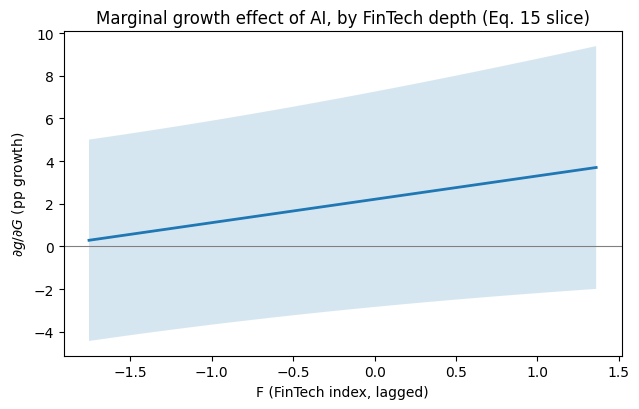

AI dividend turns positive at F > -2.02 (sample F: -0.78 to 0.95 IQR)


In [ ]:
b1 = spec1.params.get("G_l", 0); b3v = spec1.params.get("FG_l", 0)
V = spec1.cov
Fgrid = np.linspace(panel["F"].quantile(.02), panel["F"].quantile(.98), 60)
me  = b1 + b3v * Fgrid
se  = np.sqrt(V.loc["G_l","G_l"] + Fgrid**2 * V.loc["FG_l","FG_l"]
              + 2 * Fgrid * V.loc["G_l","FG_l"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(Fgrid, me, lw=2)
ax.fill_between(Fgrid, me - 1.96*se, me + 1.96*se, alpha=.18)
ax.axhline(0, color="grey", lw=.8)
ax.set_xlabel("F (FinTech index, lagged)")
ax.set_ylabel(r"$\partial g/\partial G$ (pp growth)")
ax.set_title("Marginal growth effect of AI, by FinTech depth (Eq. 15 slice)")
plt.tight_layout(); plt.show()
cross = -b1/b3v if b3v != 0 else np.nan
print(f"AI dividend turns positive at F > {cross:.2f} "
      f"(sample F: {panel['F'].quantile(.25):.2f} to {panel['F'].quantile(.75):.2f} IQR)")

## 5. Spec 2 — Full interaction (Eq. 31)

$$g_{it} = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \beta_4 FI + \beta_5 GI
+ \beta_6 GH + \beta_7 G\sigma^{KIS} + \beta_8 FGI + \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$

Tests the institutional ($\beta_4,\beta_5,\beta_8$) and absorptive-capacity
($\beta_6,\beta_7$) complementarities of Eqs. (8)–(9) and (14).

In [ ]:
spec2 = run_fe("gdp_pc_growth",
               ["F_l","G_l","FG_l","FI_l","GI_l","GH_l","GS_l","FGI_l"]
               + [f"{c}_l" for c in CONTROLS],
               panel, "Spec 2 (Eq.31)")


===== Spec 2 (Eq.31) =====  N=1,085  countries=111
                                coef      se       t      p
Intercept                   171.8432 22.7113  7.5664 0.0000
F_l                           0.6384  0.6954  0.9180 0.3589
G_l                           2.1476  2.6784  0.8018 0.4229
FG_l                          1.4206  0.7398  1.9202 0.0551
FI_l                         -0.3604  0.8691 -0.4147 0.6784
GI_l                          0.4466  0.9516  0.4693 0.6390
GH_l                          1.9232  4.1637  0.4619 0.6443
GS_l                        -23.4463 13.5280 -1.7332 0.0834
FGI_l                        -0.0861  0.6500 -0.1324 0.8947
log_gdp_l                   -17.8563  2.3744 -7.5202 0.0000
trade_pct_gdp_l               0.0505  0.0137  3.6899 0.0002
inflation_l                  -0.0157  0.0220 -0.7139 0.4755
investment_pct_gdp_l          0.0909  0.0526  1.7282 0.0843
pop_growth_l                 -0.5903  0.1457 -4.0518 0.0001
credit_to_private_pct_gdp_l  -0.0178  0.0056 -3.

## 6. Spec 3 — Displacement (Eq. 32)

$$g_{it} = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \beta_4 GH + \beta_5 G\sigma^{KIS}
+ \beta_6\, G\rho(1-H)(1-\sigma^{KIS}) + \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$

**Hypothesis: $\beta_6 < 0$** — the displacement term of Eq. (13) drags growth
where exposure $\rho$ is high and absorptive capacity $(H, \sigma^{KIS})$ is low.
Identifies $\eta_9\delta_0$ up to scale.

In [ ]:
spec3 = run_fe("gdp_pc_growth",
               ["F_l","G_l","FG_l","GH_l","GS_l","D_term_l"]
               + [f"{c}_l" for c in CONTROLS],
               panel, "Spec 3 (Eq.32)")
b6, p6 = spec3.params.get("D_term_l", np.nan), spec3.pvalues.get("D_term_l", np.nan)
print(f"\nbeta6 (displacement) = {b6:.4f}{star(p6)}  ->  hypothesis beta6<0: "
      f"{'SUPPORTED' if (b6 < 0 and p6 < .10) else 'not significant' if b6 < 0 else 'CONTRADICTED'}")


===== Spec 3 (Eq.32) =====  N=1,085  countries=111
                                coef      se       t      p
Intercept                   172.4729 21.9915  7.8427 0.0000
F_l                           0.6793  0.6371  1.0661 0.2866
G_l                           3.8361  5.1913  0.7390 0.4601
FG_l                          1.4264  0.6100  2.3382 0.0196
GH_l                         -0.3035  8.1473 -0.0372 0.9703
GS_l                        -24.8461 13.5872 -1.8286 0.0678
D_term_l                    -24.8535 62.9489 -0.3948 0.6931
log_gdp_l                   -17.8258  2.2943 -7.7696 0.0000
trade_pct_gdp_l               0.0503  0.0137  3.6835 0.0002
inflation_l                  -0.0160  0.0218 -0.7348 0.4626
investment_pct_gdp_l          0.0912  0.0519  1.7592 0.0789
pop_growth_l                 -0.6044  0.1377 -4.3877 0.0000
credit_to_private_pct_gdp_l  -0.0188  0.0060 -3.1476 0.0017
secondary_enrollment_l        0.0060  0.0136  0.4401 0.6599

beta6 (displacement) = -24.8535  ->  hypothesis

## 7. Spec 4 — Middle-income interaction (Eq. 33) — **headline**

$$g_{it} = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \delta_1 MI
+ \delta_2 (F\times MI) + \delta_3 (G\times MI) + \delta_4 (FG\times MI)
+ \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$

**Hypothesis: $\delta_4 > 0$** — the joint-digital complementarity is the
escape lever specifically for middle-income countries: $F\times G$ pays an
*extra* growth dividend inside the middle-income band.

In [ ]:
spec4 = run_fe("gdp_pc_growth",
               ["F_l","G_l","FG_l","MI_l","F_MI_l","G_MI_l","FG_MI_l"]
               + [f"{c}_l" for c in CONTROLS],
               panel, "Spec 4 (Eq.33, headline)")
d4, pd4 = spec4.params.get("FG_MI_l", np.nan), spec4.pvalues.get("FG_MI_l", np.nan)
print(f"\ndelta4 (FG x MI) = {d4:.4f}{star(pd4)}  ->  hypothesis delta4>0: "
      f"{'SUPPORTED' if (d4 > 0 and pd4 < .10) else 'not significant' if d4 > 0 else 'CONTRADICTED'}")
print(f"Joint-digital effect inside MI band: {spec4.params.get('FG_l',0)+d4:.4f}; "
      f"outside: {spec4.params.get('FG_l',0):.4f}")


===== Spec 4 (Eq.33, headline) =====  N=1,380  countries=135
                                coef      se       t      p
Intercept                   129.7603 18.1810  7.1372 0.0000
F_l                           0.5459  0.7999  0.6824 0.4951
G_l                           2.2723  2.8259  0.8041 0.4215
FG_l                          1.4636  0.6353  2.3036 0.0214
MI_l                          1.2849  0.7818  1.6434 0.1005
F_MI_l                        0.7129  0.8237  0.8655 0.3870
G_MI_l                       -0.7673  1.2634 -0.6074 0.5437
FG_MI_l                      -0.6092  0.9390 -0.6487 0.5166
log_gdp_l                   -13.9374  1.9891 -7.0070 0.0000
trade_pct_gdp_l               0.0422  0.0119  3.5374 0.0004
inflation_l                  -0.0262  0.0078 -3.3776 0.0008
investment_pct_gdp_l          0.1020  0.0407  2.5061 0.0123
pop_growth_l                 -0.3646  0.0914 -3.9873 0.0001
credit_to_private_pct_gdp_l  -0.0178  0.0060 -2.9543 0.0032
secondary_enrollment_l        0.0171  

## 8. Spec 5 — Growth-slowdown probit (Eq. 34)

$$\Pr(\text{Slowdown}_{it}=1)=\Phi\!\left(\eta + \theta_1 F + \theta_2 G + \theta_3 FG
+ \theta_4 (FG\times MI) + \Pi'X + \mu_i + \lambda_t\right)$$

**Hypotheses: $\theta_3 < 0,\ \theta_4 < 0$.**
Slowdown is operationalized Eichengreen-style: a year in which the country's
forward 3-year average growth falls at least 2 pp below its own trailing 5-year
average while still above 1% trailing growth. A probit with full country dummies
suffers the incidental-parameters problem, so we report (a) a **linear
probability model with country+year FE** and (b) a **pooled probit with year
dummies and income-group controls**.

In [ ]:
g5 = panel.groupby("iso3")["gdp_pc_growth"]
trail5 = g5.transform(lambda s: s.rolling(5, min_periods=3).mean())
fwd3   = g5.transform(lambda s: s.shift(-1).rolling(3, min_periods=2).mean()
                                .shift(-2))  # mean of t+1..t+3
panel["Slowdown"] = ((trail5 - fwd3 >= 2.0) & (trail5 >= 1.0)).astype(float)
panel.loc[fwd3.isna() | trail5.isna(), "Slowdown"] = np.nan
print("Slowdown incidence:", f"{panel['Slowdown'].mean():.3f}")

# (a) LPM with two-way FE
spec5a = run_fe("Slowdown", ["F_l","G_l","FG_l","FG_MI_l"]
                + [f"{c}_l" for c in CONTROLS], panel, "Spec 5a (Eq.34, LPM-FE)")

# (b) pooled probit, year dummies + income-group dummies
d5 = panel.dropna(subset=["Slowdown","F_l","G_l","FG_l","FG_MI_l"]
                  + [f"{c}_l" for c in CONTROLS]).copy()
d5["yr"] = d5["year"].astype(str)
ig = d5.get("income_group_hist", d5.get("income_group"))
d5["ig"] = ig.fillna("NA")
f5 = ("Slowdown ~ F_l + G_l + FG_l + FG_MI_l + "
      + " + ".join(f"{c}_l" for c in CONTROLS) + " + C(yr)") # Removed C(ig) to simplify
spec5b = smf.probit(f5, data=d5).fit(disp=0,
            cov_type="cluster", cov_kwds={"groups": d5["iso3"]})
print("\n===== Spec 5b (pooled probit) — key coefficients =====")
print(spec5b.summary2().tables[1].loc[["F_l","G_l","FG_l","FG_MI_l"]].round(4))

Slowdown incidence: 0.191

===== Spec 5a (Eq.34, LPM-FE) =====  N=1,175  countries=134
                                coef     se       t      p
Intercept                   -14.7596 2.6418 -5.5871 0.0000
F_l                          -0.2656 0.0889 -2.9860 0.0029
G_l                          -0.1621 0.3438 -0.4714 0.6374
FG_l                         -0.0793 0.1074 -0.7384 0.4604
FG_MI_l                      -0.0122 0.0981 -0.1248 0.9007
log_gdp_l                     1.5704 0.2742  5.7279 0.0000
trade_pct_gdp_l              -0.0003 0.0021 -0.1504 0.8805
inflation_l                  -0.0021 0.0044 -0.4829 0.6293
investment_pct_gdp_l          0.0087 0.0052  1.6570 0.0978
pop_growth_l                 -0.0324 0.0117 -2.7654 0.0058
credit_to_private_pct_gdp_l  -0.0029 0.0011 -2.7030 0.0070
secondary_enrollment_l       -0.0024 0.0022 -1.1083 0.2680

===== Spec 5b (pooled probit) — key coefficients =====
          Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
F_l     -0.0844    0.1498 -0.5635

## 9. Spec 7 — Vulnerability threshold (Eqs. 22, 36, 37)

The vulnerability condition (Eq. 22):
$$\eta_9\delta_0\,\rho_{i}(1-H_{it})(1-\sigma^{KIS}_{it}) \;>\;
\tilde\eta_2 + \tilde\eta_5 I_{it} + \eta_6 H_{it}\sigma^{KIS}_{it}$$

We construct $\widehat{\text{Vuln}}_{it}$ (Eq. 36) by plugging the Spec 2/3
estimates into the inequality: a country-year is *vulnerable* when its fitted
displacement drag exceeds its fitted AI dividend (i.e., the implied $a_G < 0$).
Then the exit probit (Eq. 37):
$$\Pr(\text{Exit}_{it}=1\mid \cdot) = \Phi\!\left(\kappa + \psi_1 F + \psi_2 G + \psi_3 FG
+ \psi_4 \text{Vuln}_{it} + \Omega'X + \tau_t\right)$$
where Exit = transition from middle income to high income (`income_group_hist`).
**Hypothesis: $\psi_4 < 0$.**

In [ ]:
# fitted aG per country-year, using Spec 3 estimates (Eq. 20 mapping)
e2 = spec3.params.get("G_l", 0)            # eta2~
e6 = spec3.params.get("GH_l", 0)           # eta6*H part (via GH)
e7 = spec3.params.get("GS_l", 0)           # sigma part
e9 = spec3.params.get("D_term_l", 0)       # -(eta9 delta0) sign included
gi5 = spec2.params.get("GI_l", 0)          # eta5~ from Spec 2
panel["aG_hat"] = (e2 + gi5 * panel["I"] + e6 * panel["H"] + e7 * panel["sigma_kis"]
                   + e9 * panel["rho"] * (1 - panel["H"]) * (1 - panel["sigma_kis"]))
panel["Vuln"] = (panel["aG_hat"] < 0).astype(float)
panel.loc[panel["aG_hat"].isna(), "Vuln"] = np.nan
print("Vulnerable share of country-years:", f"{panel['Vuln'].mean():.3f}")

# Exit event: MI in t-1, H in t (year-varying classification)
igh = panel.get("income_group_hist")
panel["Exit"] = ((igh.shift(1).isin(["LM","UM"])) & (igh == "H")
                 & (panel["iso3"] == panel["iso3"].shift(1))).astype(float)
risk = igh.shift(1).isin(["LM","UM"]) & (panel["iso3"] == panel["iso3"].shift(1))
d7 = panel[risk].dropna(subset=["Exit","F_l","G_l","FG_l","Vuln"]
                        + [f"{c}_l" for c in CONTROLS]).copy()
d7["yr"] = d7["year"].astype(str)
print(f"Risk set: {len(d7):,} country-years, exits: {int(d7['Exit'].sum())}")
# Exits are rare events (often <15 in 2010-2024): try a parsimonious probit,
# fall back to a linear probability model, and always report the descriptive
# exit-rate comparison, which is the honest headline with so few events.
print("\nExit rate by vulnerability status (descriptive):")
print(d7.groupby("Vuln")["Exit"].agg(["mean", "sum", "count"]).round(4))
est = None
if d7["Exit"].sum() >= 10:
    try:  # parsimonious probit: no year dummies, trimmed controls
        f7 = "Exit ~ F_l + G_l + FG_l + Vuln + log_gdp_l + investment_pct_gdp_l"
        est = smf.probit(f7, data=d7).fit(disp=0, method="bfgs", maxiter=300,
                  cov_type="cluster", cov_kwds={"groups": d7["iso3"]})
        print("\nParsimonious probit (Eq. 37):")
    except Exception as e:
        print(f"\nProbit unstable ({type(e).__name__}) — falling back to LPM.")
if est is None:
    f7 = "Exit ~ F_l + G_l + FG_l + Vuln + log_gdp_l + investment_pct_gdp_l"
    est = smf.ols(f7, data=d7).fit(cov_type="cluster",
                                   cov_kwds={"groups": d7["iso3"]})
    print("\nLinear probability model (Eq. 37, LPM):")
print(est.summary2().tables[1].loc[["F_l","G_l","FG_l","Vuln"]].round(4))
psi4 = est.params["Vuln"]
print(f"\npsi4 (Vuln) = {psi4:.4f}{star(est.pvalues['Vuln'])}  ->  hypothesis psi4<0: "
      f"{'SUPPORTED' if psi4 < 0 and est.pvalues['Vuln'] < .10 else 'right sign, n.s.' if psi4 < 0 else 'wrong sign'}")

Vulnerable share of country-years: 0.335
Risk set: 534 country-years, exits: 13

Exit rate by vulnerability status (descriptive):
         mean    sum  count
Vuln                       
0.0000 0.0080 4.0000    497
1.0000 0.2432 9.0000     37

Parsimonious probit (Eq. 37):
       Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
F_l   0.1487    0.4938  0.3013 0.7632 -0.8190  1.1165
G_l  -1.0193    0.8625 -1.1818 0.2373 -2.7098  0.6712
FG_l -1.2603    1.1725 -1.0749 0.2824 -3.5583  1.0378
Vuln  1.2233    0.4926  2.4835 0.0130  0.2579  2.1888

psi4 (Vuln) = 1.2233**  ->  hypothesis psi4<0: wrong sign


## 10. Spec 8 — Quadrant heterogeneity (Eq. 38)

$$g_{it} = \alpha + \sum_{q=1}^{4} \mathbb{1}\{q_{it}=q\}\,(\beta_1^q F + \beta_2^q G + \beta_3^q FG)
+ \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$

Quadrants by median splits of $H$ and $\sigma^{KIS}$.
**Predicted ordering: $\beta_3^{HH} > \beta_3^{HL}, \beta_3^{LH} > \beta_3^{LL}$** —
the joint-digital payoff is largest where absorptive capacity is highest.


===== Spec 8 (Eq.38) =====  N=1,114  countries=112
                                coef      se       t      p
Intercept                   177.5597 21.5028  8.2575 0.0000
F_l_HH                        2.2346  0.9042  2.4712 0.0136
G_l_HH                        0.0950  3.4730  0.0273 0.9782
FG_l_HH                      -0.3263  1.2814 -0.2547 0.7990
F_l_HL                        1.3160  0.7435  1.7701 0.0770
G_l_HL                        0.7636  3.0758  0.2483 0.8040
FG_l_HL                      -0.0566  1.1245 -0.0504 0.9598
F_l_LH                       -2.9238  0.7853 -3.7233 0.0002
G_l_LH                        4.1877  2.9342  1.4272 0.1538
FG_l_LH                       5.3841  1.1492  4.6853 0.0000
F_l_LL                        0.7665  0.6008  1.2757 0.2024
G_l_LL                        2.4774  2.7368  0.9052 0.3656
FG_l_LL                       1.7415  0.6896  2.5253 0.0117
log_gdp_l                   -18.5911  2.2553 -8.2433 0.0000
trade_pct_gdp_l               0.0525  0.0138  3.

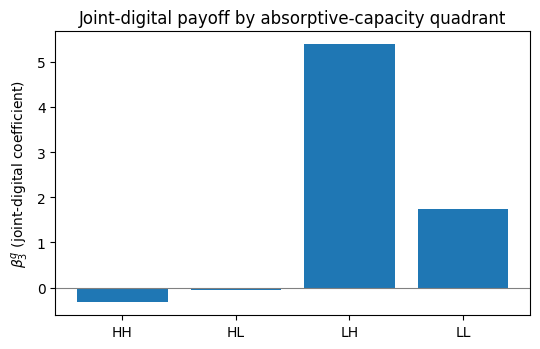

{'HH': np.float64(-0.3263), 'HL': np.float64(-0.0566), 'LH': np.float64(5.3841), 'LL': np.float64(1.7415)} 
Predicted ordering HH > HL, LH > LL: partially / not supported


In [ ]:
medH, medS = panel["H"].median(), panel["sigma_kis"].median()
panel["quad"] = np.select(
    [ (panel["H"]>=medH)&(panel["sigma_kis"]>=medS),
      (panel["H"]>=medH)&(panel["sigma_kis"]< medS),
      (panel["H"]< medH)&(panel["sigma_kis"]>=medS),
      (panel["H"]< medH)&(panel["sigma_kis"]< medS) ],
    ["HH","HL","LH","LL"], default=None)

regs = []
for q in ["HH","HL","LH","LL"]:
    for v in ["F_l","G_l","FG_l"]:
        col = f"{v}_{q}"
        panel[col] = panel[v] * (panel["quad"] == q)
        regs.append(col)
spec8 = run_fe("gdp_pc_growth", regs + [f"{c}_l" for c in CONTROLS],
               panel.dropna(subset=["quad"]), "Spec 8 (Eq.38)")

b3q = {q: spec8.params.get(f"FG_l_{q}", np.nan) for q in ["HH","HL","LH","LL"]}
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(b3q.keys(), b3q.values())
ax.axhline(0, color="grey", lw=.8)
ax.set_ylabel(r"$\beta_3^q$ (joint-digital coefficient)")
ax.set_title("Joint-digital payoff by absorptive-capacity quadrant")
plt.tight_layout(); plt.show()
print({k: round(v,4) for k,v in b3q.items()},
      "\nPredicted ordering HH > HL, LH > LL:",
      "SUPPORTED" if (b3q["HH"] > b3q["HL"] and b3q["HH"] > b3q["LH"]
                      and min(b3q["HL"], b3q["LH"]) > b3q["LL"]) else "partially / not supported")

## 11. Spec 9 — Empirical escape frontier (Eqs. 19–21, 39)

From the linearized escape condition $a_F F + a_G G + a_{FG} FG \geq \bar g$ (Eq. 19),
the frontier (Eq. 21/39) is
$$\hat F^*(G) = \frac{\bar g - \hat a_G\, G}{\hat a_F + \hat a_{FG}\, G}$$
with $\hat a_F=\hat\beta_1,\ \hat a_G=\hat\beta_2,\ \hat a_{FG}=\hat\beta_3$ from
Spec 1, and $\bar g$ = the growth premium required for convergence (we use the
75th-percentile in-sample growth gap, and show $\bar g \in \{1, 2, 3\}$ pp).
Countries above the curve satisfy the escape condition.

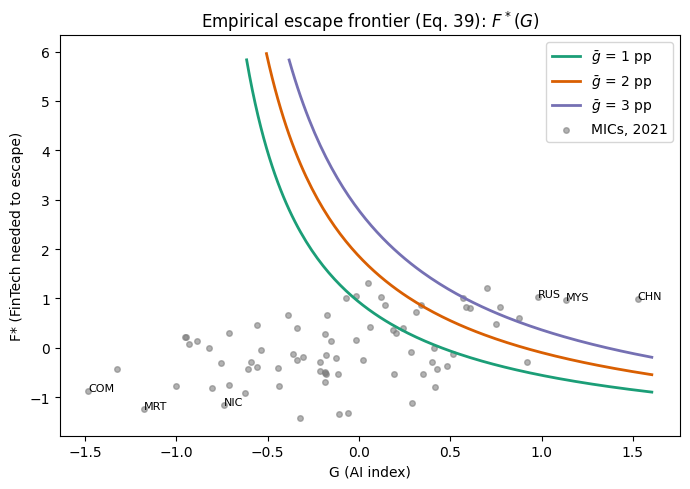

In [ ]:
aF = spec1.params.get("F_l", np.nan)
aG = spec1.params.get("G_l", np.nan)
aFG = spec1.params.get("FG_l", np.nan)
Gg = np.linspace(panel["G"].quantile(.02), panel["G"].quantile(.98), 200)

fig, ax = plt.subplots(figsize=(7, 5))
for gbar, c in zip([1.0, 2.0, 3.0], ["#1b9e77", "#d95f02", "#7570b3"]):
    denom = aF + aFG * Gg
    Fstar = np.where(np.abs(denom) > 1e-6, (gbar - aG * Gg) / denom, np.nan)
    Fstar = np.where((Fstar > -4) & (Fstar < 6), Fstar, np.nan)
    ax.plot(Gg, Fstar, color=c, lw=2, label=fr"$\bar g$ = {gbar:.0f} pp")
mi21 = panel[(panel["year"] == 2021) & (panel["MI"] == 1)].dropna(subset=["F","G"])
ax.scatter(mi21["G"], mi21["F"], s=16, alpha=.6, color="grey", label="MICs, 2021")
for _, r in mi21.nlargest(6, "FG").iterrows():
    ax.annotate(r["iso3"], (r["G"], r["F"]), fontsize=8)
ax.set_xlabel("G (AI index)"); ax.set_ylabel("F* (FinTech needed to escape)")
ax.set_title("Empirical escape frontier (Eq. 39): $F^*(G)$")
ax.legend(); plt.tight_layout(); plt.show()

## 12. Spec 10 — Threshold regression (Eq. 40)

$$g_{it}=\begin{cases}\alpha_L+\beta_L (F G)_{it}+\Gamma'X+\mu_i+\lambda_t+\varepsilon_{it}
& (F\cdot G)_{it}<\gamma\\[2pt]
\alpha_H+\beta_H (F G)_{it}+\Gamma'X+\mu_i+\lambda_t+\varepsilon_{it}
& (F\cdot G)_{it}\ge\gamma\end{cases}$$

$\gamma$ chosen by SSR grid search (Hansen-style) over the inner 70% of the
$F\cdot G$ distribution. **Hypothesis: $\beta_H > \beta_L$** — the joint-digital
payoff kicks in above a critical penetration level.

In [ ]:
dth = panel.dropna(subset=["gdp_pc_growth","FG_l"]
                  + [f"{c}_l" for c in CONTROLS]).copy()
grid = np.quantile(dth["FG_l"], np.linspace(.15, .85, 36))
best = (None, np.inf)
for gam in grid:
    dth["FG_lo"] = dth["FG_l"] * (dth["FG_l"] <  gam)
    dth["FG_hi"] = dth["FG_l"] * (dth["FG_l"] >= gam)
    di = dth.set_index(["iso3","year"])
    r = PanelOLS.from_formula(
        "gdp_pc_growth ~ 1 + FG_lo + FG_hi + "
        + " + ".join(f"{c}_l" for c in CONTROLS)
        + " + EntityEffects + TimeEffects", data=di, drop_absorbed=True
    ).fit(cov_type="clustered", cluster_entity=True)
    ssr = float((r.resids**2).sum())
    if ssr < best[1]:
        best = (gam, ssr, r)
gamma_hat, _, spec10 = best
RESULTS["Spec 10 (Eq.40)"] = spec10
bL, bH = spec10.params["FG_lo"], spec10.params["FG_hi"]
print(f"Estimated threshold gamma = {gamma_hat:.3f}")
print(f"beta_L = {bL:.4f}{star(spec10.pvalues['FG_lo'])}, "
      f"beta_H = {bH:.4f}{star(spec10.pvalues['FG_hi'])}  ->  "
      f"hypothesis beta_H > beta_L: {'SUPPORTED' if bH > bL else 'CONTRADICTED'}")

Estimated threshold gamma = 0.351
beta_L = -1.5498, beta_H = 0.8224*  ->  hypothesis beta_H > beta_L: SUPPORTED


## 13. Spec 14 — Dynamic panel (Eq. 47)

$$g_{it} = \rho\, g_{i,t-1} + \beta_1 F_{it-1} + \beta_2 G_{it-1}
+ \beta_3 F_{it-1}G_{it-1} + \Gamma'X_{it-1} + \mu_i + \lambda_t + \varepsilon_{it}$$

The paper specifies Blundell–Bond **system GMM** with AR(2) and Hansen
diagnostics. As a transparent first pass we report the dynamic FE-OLS version
(with the standard Nickell-bias caveat: with $T \approx 14$ the bias on $\rho$
is of order $-1/T$, while $\beta_3$ is far less affected). For publication, run
this spec in Stata `xtabond2` or Python `pydynpd`.

In [ ]:
panel["g_l"] = panel.groupby("iso3")["gdp_pc_growth"].shift(1)
spec14 = run_fe("gdp_pc_growth",
                ["g_l","F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
                panel, "Spec 14 (Eq.47, dynamic FE)")


===== Spec 14 (Eq.47, dynamic FE) =====  N=1,380  countries=135
                                coef      se       t      p
Intercept                   131.3214 17.5097  7.4999 0.0000
g_l                           0.0116  0.0473  0.2460 0.8058
F_l                           1.0829  0.5628  1.9241 0.0546
G_l                           2.2349  2.5768  0.8673 0.3859
FG_l                          1.0980  0.5240  2.0953 0.0364
log_gdp_l                   -14.0295  1.8921 -7.4146 0.0000
trade_pct_gdp_l               0.0422  0.0118  3.5826 0.0004
inflation_l                  -0.0269  0.0071 -3.7721 0.0002
investment_pct_gdp_l          0.1030  0.0409  2.5194 0.0119
pop_growth_l                 -0.3594  0.1113 -3.2309 0.0013
credit_to_private_pct_gdp_l  -0.0169  0.0061 -2.7643 0.0058
secondary_enrollment_l        0.0163  0.0142  1.1517 0.2497


## 14. Summary — predicted signs vs. estimates

Collects each paper hypothesis and the estimated coefficient with significance
stars (\*\*\* p<0.01, \*\* p<0.05, \* p<0.10).

In [ ]:
rows = []
def add(spec, par, pred, label):
    if spec in RESULTS and par in RESULTS[spec].params:
        b, p = RESULTS[spec].params[par], RESULTS[spec].pvalues[par]
        ok = (b > 0) if pred == "+" else (b < 0)
        rows.append({"Spec": spec, "Parameter": label, "Predicted": pred,
                     "Estimate": round(b, 4), "Sig": star(p),
                     "Verdict": ("supported" if ok and p < .10 else
                                 "right sign, n.s." if ok else "wrong sign")})

add("Spec 1 (Eq.30)",  "FG_l",    "+", "beta3: F x G")
add("Spec 2 (Eq.31)",  "FGI_l",   "+", "beta8: F x G x I")
add("Spec 3 (Eq.32)",  "D_term_l","-", "beta6: displacement")
add("Spec 4 (Eq.33, headline)", "FG_MI_l", "+", "delta4: FG x MI (headline)")
add("Spec 5a (Eq.34, LPM-FE)",  "FG_l",    "-", "theta3: FG -> slowdown")
add("Spec 5a (Eq.34, LPM-FE)",  "FG_MI_l", "-", "theta4: FG x MI -> slowdown")
add("Spec 14 (Eq.47, dynamic FE)", "FG_l", "+", "beta3 (dynamic)")

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

print("\nReading guide: the theory survives if beta3>0 (Spec 1), delta4>0 "
      "(Spec 4) and beta6<0 (Spec 3) hold jointly; the frontier plot (Spec 9) "
      "then gives the policy translation — how much FinTech depth a middle-"
      "income country needs at its current AI level to satisfy the escape "
      "condition (Eq. 17).")

                       Spec                   Parameter Predicted  Estimate Sig          Verdict
             Spec 1 (Eq.30)                beta3: F x G         +    1.0956  **        supported
             Spec 2 (Eq.31)            beta8: F x G x I         +   -0.0861           wrong sign
             Spec 3 (Eq.32)         beta6: displacement         -  -24.8535     right sign, n.s.
   Spec 4 (Eq.33, headline)  delta4: FG x MI (headline)         +   -0.6092           wrong sign
    Spec 5a (Eq.34, LPM-FE)      theta3: FG -> slowdown         -   -0.0793     right sign, n.s.
    Spec 5a (Eq.34, LPM-FE) theta4: FG x MI -> slowdown         -   -0.0122     right sign, n.s.
Spec 14 (Eq.47, dynamic FE)             beta3 (dynamic)         +    1.0980  **        supported

Reading guide: the theory survives if beta3>0 (Spec 1), delta4>0 (Spec 4) and beta6<0 (Spec 3) hold jointly; the frontier plot (Spec 9) then gives the policy translation — how much FinTech depth a middle-income country need

## 15. Robustness battery — diagnosing $\beta_3$ (n.s.) and $\delta_4 < 0$

The headline table can be misleading for three mechanical reasons, each tested
below. The comparison table at the end shows $\beta_3$ (Spec 1) and $\delta_4$
(Spec 4) across all variants.

| # | Variant | What it tests |
|---|---|---|
| R1 | Drop 2020–2021 | COVID collapse hit MICs' growth while AI activity surged — a spurious negative $FG\times MI$ |
| R2 | Wave-years-only $F$ (no interpolation) | Interpolation measurement error attenuates interactions |
| R3 | 3-year forward-average growth | Annual growth is noisy; growth regressions conventionally average |
| R4 | Exclude China | CHN dominates the AI-publications pillar while its growth slowed |
| R5 | Standardized displacement term | Makes $\beta_6$ readable (per-SD effect) |
| R6 | Between (cross-section) estimator | Country FE absorb the GARI/AIPI pillars; the between estimator uses the full cross-sectional $G$ variation the theory is mostly about |

In [ ]:
ROB = []

def grab(res, par, label, variant):
    if par in res.params:
        ROB.append({"Variant": variant, "Param": label,
                    "Estimate": round(res.params[par], 4),
                    "p": round(res.pvalues[par], 3),
                    "Sig": star(res.pvalues[par])})

def run_pair(df, variant, depvar="gdp_pc_growth", Fcol=None):
    d = df.copy()
    if Fcol is not None:   # swap in an alternative F and rebuild interactions/lags
        d["F"] = d[Fcol]
        d["FG"] = d["F"] * d["G"]
        d["F_MI"] = d["F"] * d["MI"]; d["FG_MI"] = d["FG"] * d["MI"]
        for v in ["F","FG","F_MI","FG_MI"]:
            d[f"{v}_l"] = d.groupby("iso3")[v].shift(1)
    s1 = run_fe(depvar, ["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
                d, f"{variant} / Spec1")
    grab(s1, "FG_l", "beta3 (FxG)", variant)
    s4 = run_fe(depvar, ["F_l","G_l","FG_l","MI_l","F_MI_l","G_MI_l","FG_MI_l"]
                + [f"{c}_l" for c in CONTROLS], d, f"{variant} / Spec4")
    grab(s4, "FG_MI_l", "delta4 (FGxMI)", variant)
    return s1, s4

# baseline for reference
grab(RESULTS["Spec 1 (Eq.30)"], "FG_l", "beta3 (FxG)", "Baseline")
grab(RESULTS["Spec 4 (Eq.33, headline)"], "FG_MI_l", "delta4 (FGxMI)", "Baseline")

In [ ]:
# R1 — drop COVID years
run_pair(panel[~panel["year"].isin([2020, 2021])], "R1 no-COVID");


===== R1 no-COVID / Spec1 =====  N=1,155  countries=134
                                coef      se       t      p
Intercept                   106.7854 17.8314  5.9886 0.0000
F_l                           0.8472  0.5398  1.5695 0.1168
G_l                           1.9665  2.3048  0.8532 0.3937
FG_l                          0.4915  0.5042  0.9747 0.3299
log_gdp_l                   -11.2509  1.9219 -5.8539 0.0000
trade_pct_gdp_l               0.0395  0.0112  3.5433 0.0004
inflation_l                  -0.0235  0.0069 -3.3849 0.0007
investment_pct_gdp_l          0.0669  0.0384  1.7427 0.0817
pop_growth_l                 -0.4937  0.1105 -4.4674 0.0000
credit_to_private_pct_gdp_l  -0.0197  0.0075 -2.6369 0.0085
secondary_enrollment_l        0.0113  0.0137  0.8284 0.4076

===== R1 no-COVID / Spec4 =====  N=1,155  countries=134
                                coef      se       t      p
Intercept                   105.5403 18.0548  5.8456 0.0000
F_l                           0.7719  0.6538  

In [ ]:
# R2 — wave-years-only F (no interpolation)
run_pair(panel, "R2 wave-F", Fcol="F_wave");


===== R2 wave-F / Spec1 =====  N=412  countries=129
                               coef      se       t      p
Intercept                   71.2786 32.6124  2.1856 0.0297
F_l                         -0.2147  0.9989 -0.2150 0.8300
G_l                         -1.1588  4.2807 -0.2707 0.7868
FG_l                        -0.0623  0.9598 -0.0649 0.9483
log_gdp_l                   -7.5465  3.2553 -2.3182 0.0212
trade_pct_gdp_l              0.0487  0.0234  2.0779 0.0387
inflation_l                 -0.0255  0.0151 -1.6917 0.0919
investment_pct_gdp_l         0.0724  0.0691  1.0481 0.2955
pop_growth_l                -0.4216  0.1875 -2.2485 0.0254
credit_to_private_pct_gdp_l -0.0247  0.0167 -1.4802 0.1400
secondary_enrollment_l       0.0116  0.0210  0.5525 0.5810

===== R2 wave-F / Spec4 =====  N=412  countries=129
                               coef      se       t      p
Intercept                   69.0822 31.1572  2.2172 0.0275
F_l                          1.1214  1.2578  0.8916 0.3734
G_l      

In [ ]:
# R3 — 3-year forward-average growth as outcome
panel["g3f"] = (panel.groupby("iso3")["gdp_pc_growth"]
                .transform(lambda s: s.rolling(3, min_periods=2).mean().shift(-2)))
run_pair(panel, "R3 g(3yr-fwd)", depvar="g3f");


===== R3 g(3yr-fwd) / Spec1 =====  N=1,177  countries=134
                                coef      se       t      p
Intercept                   128.8164 13.5640  9.4969 0.0000
F_l                           0.8211  0.4528  1.8136 0.0700
G_l                          -0.5646  1.8982 -0.2975 0.7662
FG_l                          0.8943  0.3867  2.3128 0.0209
log_gdp_l                   -13.5093  1.4392 -9.3865 0.0000
trade_pct_gdp_l               0.0258  0.0076  3.4067 0.0007
inflation_l                  -0.0101  0.0127 -0.7941 0.4273
investment_pct_gdp_l          0.0319  0.0217  1.4691 0.1421
pop_growth_l                  0.1038  0.1178  0.8817 0.3782
credit_to_private_pct_gdp_l  -0.0096  0.0049 -1.9501 0.0514
secondary_enrollment_l        0.0190  0.0118  1.6018 0.1095

===== R3 g(3yr-fwd) / Spec4 =====  N=1,177  countries=134
                                coef      se       t      p
Intercept                   127.2728 13.5741  9.3762 0.0000
F_l                           0.7440  0.52

In [ ]:
# R4 — exclude China (dominates the AI-publications pillar)
run_pair(panel[panel["iso3"] != "CHN"], "R4 ex-CHN");


===== R4 ex-CHN / Spec1 =====  N=1,378  countries=134
                                coef      se       t      p
Intercept                   130.6226 17.9846  7.2630 0.0000
F_l                           1.0777  0.5614  1.9197 0.0551
G_l                           2.2110  2.5756  0.8585 0.3908
FG_l                          1.0943  0.5232  2.0916 0.0367
log_gdp_l                   -13.9588  1.9426 -7.1855 0.0000
trade_pct_gdp_l               0.0426  0.0117  3.6304 0.0003
inflation_l                  -0.0274  0.0075 -3.6485 0.0003
investment_pct_gdp_l          0.1046  0.0394  2.6580 0.0080
pop_growth_l                 -0.3691  0.0895 -4.1234 0.0000
credit_to_private_pct_gdp_l  -0.0172  0.0060 -2.8914 0.0039
secondary_enrollment_l        0.0163  0.0142  1.1448 0.2525

===== R4 ex-CHN / Spec4 =====  N=1,378  countries=134
                                coef      se       t      p
Intercept                   129.7857 18.1840  7.1374 0.0000
F_l                           0.5458  0.7998  0.68

In [ ]:
# R5 — standardized displacement term in Spec 3 (per-SD coefficient)
panel["D_z"] = zscore(panel["D_term"])
panel["D_z_l"] = panel.groupby("iso3")["D_z"].shift(1)
s3z = run_fe("gdp_pc_growth",
             ["F_l","G_l","FG_l","GH_l","GS_l","D_z_l"]
             + [f"{c}_l" for c in CONTROLS], panel, "R5 / Spec3 (D z-scored)")
b, p = s3z.params.get("D_z_l", np.nan), s3z.pvalues.get("D_z_l", np.nan)
print(f"\nDisplacement effect per 1 SD of exposure: {b:.3f} pp of growth{star(p)} "
      f"(this is the readable version of the baseline beta6 = -113 on the raw scale)")


===== R5 / Spec3 (D z-scored) =====  N=1,085  countries=111
                                coef      se       t      p
Intercept                   171.8953 22.0632  7.7911 0.0000
F_l                           0.6793  0.6371  1.0661 0.2866
G_l                           3.8361  5.1913  0.7390 0.4601
FG_l                          1.4264  0.6100  2.3382 0.0196
GH_l                         -0.3035  8.1473 -0.0372 0.9703
GS_l                        -24.8461 13.5872 -1.8286 0.0678
D_z_l                        -1.0928  2.7679 -0.3948 0.6931
log_gdp_l                   -17.8258  2.2943 -7.7696 0.0000
trade_pct_gdp_l               0.0503  0.0137  3.6835 0.0002
inflation_l                  -0.0160  0.0218 -0.7348 0.4626
investment_pct_gdp_l          0.0912  0.0519  1.7592 0.0789
pop_growth_l                 -0.6044  0.1377 -4.3877 0.0000
credit_to_private_pct_gdp_l  -0.0188  0.0060 -3.1476 0.0017
secondary_enrollment_l        0.0060  0.0136  0.4401 0.6599

Displacement effect per 1 SD of exposu

In [ ]:
# R6 — between estimator: country means, OLS with income-group dummies.
# Country FE absorb GARI/AIPI entirely; the between estimator uses the
# cross-sectional G variation the theory mostly speaks to. Identification is
# weaker (no within-country control), so read as descriptive complement.
bt = (panel.groupby("iso3")
      .agg({**{c: "mean" for c in ["gdp_pc_growth","F","G","FG","MI"] + CONTROLS},
            "income_group": "first"})
      .dropna().reset_index())
bt["FG_MI"] = bt["FG"] * bt["MI"]; bt["F_MI"] = bt["F"]*bt["MI"]; bt["G_MI"] = bt["G"]*bt["MI"]
fbt = ("gdp_pc_growth ~ F + G + FG + MI + F_MI + G_MI + FG_MI + "
       + " + ".join(CONTROLS))
btres = smf.ols(fbt, data=bt).fit(cov_type="HC1")
print(f"Between estimator: {len(bt)} countries")
print(btres.summary2().tables[1].loc[["F","G","FG","FG_MI"]].round(4))
ROB.append({"Variant": "R6 between", "Param": "beta3 (FxG)",
            "Estimate": round(btres.params["FG"], 4),
            "p": round(btres.pvalues["FG"], 3), "Sig": star(btres.pvalues["FG"])})
ROB.append({"Variant": "R6 between", "Param": "delta4 (FGxMI)",
            "Estimate": round(btres.params["FG_MI"], 4),
            "p": round(btres.pvalues["FG_MI"], 3), "Sig": star(btres.pvalues["FG_MI"])})

Between estimator: 139 countries
        Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
F     -0.2618    0.5760 -0.4546 0.6494 -1.3907  0.8670
G      1.0019    0.5474  1.8304 0.0672 -0.0709  2.0747
FG    -0.5810    0.2018 -2.8798 0.0040 -0.9765 -0.1856
FG_MI  0.1579    0.5187  0.3043 0.7609 -0.8588  1.1745


In [ ]:
rob_tab = (pd.DataFrame(ROB)
           .drop_duplicates(subset=['Variant', 'Param'])
           .pivot(index="Variant", columns="Param", values=["Estimate","Sig"]))
print("=== Robustness comparison: beta3 and delta4 across variants ===")
print(rob_tab.to_string())

print('''
How to read this:
- If delta4 turns positive (or shrinks toward zero) in R1/R4, the baseline
  negative was driven by COVID years / China composition, not by the theory failing.
- If beta3 strengthens in R2/R3, the baseline n.s. reflects interpolation noise
  and annual-growth noise (attenuation), as suspected.
- If R6 shows beta3 > 0 significant in the cross-section, the complementarity
  is real but lives in between-country variation that country FE absorb —
  the single biggest power upgrade is then mapping the remaining four Findex
  components so F has genuine within-country variation.''')

=== Robustness comparison: beta3 and delta4 across variants ===
                 Estimate                        Sig               
Param         beta3 (FxG) delta4 (FGxMI) beta3 (FxG) delta4 (FGxMI)
Variant                                                            
Baseline           1.0956        -0.6092          **               
R1 no-COVID        0.4915         0.2688                           
R2 wave-F         -0.0623        -1.2926                           
R3 g(3yr-fwd)      0.8943         0.0485          **               
R4 ex-CHN          1.0943        -0.6109          **               
R6 between        -0.5810         0.1579         ***               

How to read this:
- If delta4 turns positive (or shrinks toward zero) in R1/R4, the baseline
  negative was driven by COVID years / China composition, not by the theory failing.
- If beta3 strengthens in R2/R3, the baseline n.s. reflects interpolation noise
  and annual-growth noise (attenuation), as suspected.
- If R6 sh

## 16. Inequality channel — primed specifications (equations_with_inequality.pdf)

Requires the Gini columns from data-acquisition **Section 7h** (`gini_disp`,
`gini_mkt`, `gini_disp_hist`). Per **Eq. (29′)**:
$$Z^{Gini}_{it} = \frac{Gini_{it} - \overline{Gini}}{\sigma_{Gini}}, \qquad Gini_{it}\in[0,1] \text{ from SWIID}$$

The six channels and where each is tested below:

| Channel | Theory term | Test |
|---|---|---|
| 1. Productivity drag | $-\eta_{10}Gini$ | $\beta_4<0$ in Spec 1′; $\phi_1<0$ in Spec 4′ |
| 2. AI-dividend erosion | $-\eta_{11}G\,Gini$ | $\beta_{10}<0$ in Spec 2′ |
| 3. Joint-digital erosion (**headline**) | $-\eta_{12}FG\,Gini$ | $\beta_{11}<0$ in Spec 2′; $\phi_4<0$ in Spec 4′ |
| 4. Displacement amplification | $\delta_1$ | $\beta_7<0$ in Spec 3′ |
| 5. Vulnerability-set expansion | Eq. 22′ | $|\widetilde{Vuln}| > |Vuln|$ |
| 6. Indirect AI→inequality→growth | $\gamma_1\cdot\theta$ | Specs 15–16 |

In [ ]:
# ---- Gini variables (Eq. 29') ----
if "gini_disp" not in panel.columns:
    raise KeyError("gini_disp missing — re-run data acquisition with Section 7h "
                   "(SWIID) and rebuild the panel.")
# SWIID series often end 1-2 years early: carry forward within country (max 3y)
panel["gini"] = (panel.groupby("iso3")["gini_disp"]
                 .transform(lambda s: s.ffill(limit=3)))
panel["Z_gini"] = zscore(panel["gini"])
print(f"Gini coverage: {panel['gini'].notna().mean():.3f} "
      f"(mean {panel['gini'].mean():.3f}, sd {panel['gini'].std():.3f})")

# interactions (z-scored Gini keeps scales comparable across specs)
panel["G_Gini"]     = panel["G"]  * panel["Z_gini"]
panel["FG_Gini"]    = panel["FG"] * panel["Z_gini"]
panel["D_Gini"]     = panel["D_term"] * panel["Z_gini"]
panel["Gini_MI"]    = panel["Z_gini"] * panel["MI"]
panel["G_Gini_MI"]  = panel["G_Gini"]  * panel["MI"]
panel["FG_Gini_MI"] = panel["FG_Gini"] * panel["MI"]
for v in ["Z_gini","G_Gini","FG_Gini","D_Gini","Gini_MI","G_Gini_MI","FG_Gini_MI"]:
    panel[f"{v}_l"] = panel.groupby("iso3")[v].shift(1)
INEQ = {}

Gini coverage: 0.746 (mean 0.380, sd 0.077)


### Spec 1′ — Baseline with inequality (Eq. 30′)
$$g_{it} = \alpha + \beta_1 F_{it-1} + \beta_2 G_{it-1} + \beta_3 (F{\times}G)_{it-1}
+ \beta_4 Gini_{it-1} + \Gamma'X_{it-1} + \mu_i + \lambda_t + \varepsilon_{it}$$
**Hypotheses: $\beta_3>0$, $\beta_4<0$** (Berg–Ostry level drag).

In [ ]:
spec1p = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","Z_gini_l"] + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 1' (Eq.30')")
INEQ["beta4 (Gini level)"] = ("Spec 1' (Eq.30')", "Z_gini_l", "-")


===== Spec 1' (Eq.30') =====  N=1,316  countries=130
                                coef      se       t      p
Intercept                   130.7983 18.9150  6.9151 0.0000
F_l                           0.9670  0.5611  1.7236 0.0851
G_l                           2.1108  2.6969  0.7827 0.4340
FG_l                          1.1748  0.5295  2.2188 0.0267
Z_gini_l                     -0.2364  0.9191 -0.2572 0.7971
log_gdp_l                   -14.0493  2.0415 -6.8817 0.0000
trade_pct_gdp_l               0.0424  0.0124  3.4339 0.0006
inflation_l                  -0.0268  0.0079 -3.4091 0.0007
investment_pct_gdp_l          0.1311  0.0381  3.4463 0.0006
pop_growth_l                 -0.3737  0.1060 -3.5245 0.0004
credit_to_private_pct_gdp_l  -0.0132  0.0050 -2.6278 0.0087
secondary_enrollment_l        0.0145  0.0143  1.0172 0.3093


### Spec 2′ — Full interaction with inequality (Eq. 31′)
$$g = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \beta_4 FI + \beta_5 GI + \beta_6 GH
+ \beta_7 G\sigma^{KIS} + \beta_8 FGI + \beta_9 Gini + \beta_{10}(G{\times}Gini)
+ \beta_{11}(FG{\times}Gini) + \Gamma'X + \mu_i + \lambda_t + \varepsilon$$
**Hypotheses: $\beta_9<0,\ \beta_{10}<0,\ \beta_{11}<0$.** $\beta_{11}$ is the
structural counterpart of $-\eta_{12}$ — the central new mechanism.

In [ ]:
spec2p = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","FI_l","GI_l","GH_l","GS_l","FGI_l",
     "Z_gini_l","G_Gini_l","FG_Gini_l"] + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 2' (Eq.31')")
INEQ["beta10 (G x Gini)"]  = ("Spec 2' (Eq.31')", "G_Gini_l", "-")
INEQ["beta11 (FG x Gini)"] = ("Spec 2' (Eq.31')", "FG_Gini_l", "-")


===== Spec 2' (Eq.31') =====  N=1,039  countries=108
                                coef      se       t      p
Intercept                   165.8190 23.4870  7.0600 0.0000
F_l                           0.6512  0.7491  0.8693 0.3849
G_l                           2.7952  2.6689  1.0473 0.2952
FG_l                          1.0870  0.8014  1.3564 0.1753
FI_l                         -0.1170  0.8532 -0.1371 0.8910
GI_l                          0.5292  0.9580  0.5524 0.5808
GH_l                          0.9939  4.7542  0.2091 0.8344
GS_l                        -24.0111 14.0730 -1.7062 0.0883
FGI_l                        -0.4051  0.6608 -0.6130 0.5400
Z_gini_l                      0.5261  1.3612  0.3865 0.6992
G_Gini_l                     -1.5509  1.2359 -1.2548 0.2099
FG_Gini_l                    -0.1176  0.6993 -0.1681 0.8665
log_gdp_l                   -17.3239  2.4550 -7.0565 0.0000
trade_pct_gdp_l               0.0477  0.0145  3.3017 0.0010
inflation_l                  -0.0183  0.0245 -

### Spec 3′ — Displacement with inequality amplifier (Eq. 32′)
$$g = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \beta_4 GH + \beta_5 G\sigma^{KIS}
+ \beta_6\, G\rho(1{-}H)(1{-}\sigma^{KIS}) + \beta_7\, G\rho(1{-}H)(1{-}\sigma^{KIS}){\times}Gini
+ \Gamma'X + \mu_i + \lambda_t + \varepsilon$$
**Hypotheses: $\beta_6<0$ and $\beta_7<0$** — $\beta_7$ identifies $\delta_1$,
the multiplicative inequality amplifier of Eq. (13′).

In [ ]:
spec3p = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","GH_l","GS_l","D_term_l","D_Gini_l"]
    + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 3' (Eq.32')")
INEQ["beta7 (D x Gini)"] = ("Spec 3' (Eq.32')", "D_Gini_l", "-")


===== Spec 3' (Eq.32') =====  N=1,039  countries=108
                                coef      se       t      p
Intercept                   163.3627 22.9871  7.1067 0.0000
F_l                           0.6170  0.6821  0.9045 0.3660
G_l                           0.9375  5.3343  0.1757 0.8605
FG_l                          1.1777  0.6262  1.8807 0.0603
GH_l                          3.6460  8.0376  0.4536 0.6502
GS_l                        -22.1057 13.8817 -1.5924 0.1116
D_term_l                      9.7187 60.1768  0.1615 0.8717
D_Gini_l                     -9.4733 14.8281 -0.6389 0.5231
log_gdp_l                   -17.0670  2.3967 -7.1212 0.0000
trade_pct_gdp_l               0.0488  0.0142  3.4425 0.0006
inflation_l                  -0.0186  0.0233 -0.7977 0.4252
investment_pct_gdp_l          0.1122  0.0526  2.1324 0.0332
pop_growth_l                 -0.6930  0.1879 -3.6881 0.0002
credit_to_private_pct_gdp_l  -0.0152  0.0062 -2.4482 0.0145
secondary_enrollment_l        0.0072  0.0143  

### Spec 4′ — Middle-income interaction with inequality (Eq. 33′) — **headline**
$$g = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \delta_1 MI + \delta_2(F{\times}MI)
+ \delta_3(G{\times}MI) + \delta_4(FG{\times}MI) + \phi_1 Gini + \phi_2(Gini{\times}MI)
+ \phi_3(G{\times}Gini{\times}MI) + \phi_4(FG{\times}Gini{\times}MI) + \Gamma'X + \mu_i + \lambda_t + \varepsilon$$
**Headline joint test: $\delta_4 > 0$ and $\phi_4 < 0$** — joint digital is the
MIT-escape lever *except* where inequality is high enough to extinguish it.
(Note: if $\phi_4<0$, the baseline $\delta_4\approx 0$ found earlier is exactly
what averaging over low- and high-Gini MICs would produce.)

In [ ]:
spec4p = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","MI_l","F_MI_l","G_MI_l","FG_MI_l",
     "Z_gini_l","Gini_MI_l","G_Gini_MI_l","FG_Gini_MI_l"]
    + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 4' (Eq.33', headline)")
INEQ["delta4' (FG x MI)"]        = ("Spec 4' (Eq.33', headline)", "FG_MI_l", "+")
INEQ["phi1 (Gini)"]              = ("Spec 4' (Eq.33', headline)", "Z_gini_l", "-")
INEQ["phi4 (FG x Gini x MI)"]    = ("Spec 4' (Eq.33', headline)", "FG_Gini_MI_l", "-")
d4 = spec4p.params.get("FG_MI_l", np.nan); p4 = spec4p.params.get("FG_Gini_MI_l", np.nan)
print(f"\nJoint-digital effect for an MI country at mean Gini: "
      f"{spec4p.params.get('FG_l',0)+d4:.3f}; at +1 SD Gini: "
      f"{spec4p.params.get('FG_l',0)+d4+p4:.3f}; at -1 SD Gini: "
      f"{spec4p.params.get('FG_l',0)+d4-p4:.3f}")


===== Spec 4' (Eq.33', headline) =====  N=1,316  countries=130
                                coef      se       t      p
Intercept                   132.7865 20.6909  6.4176 0.0000
F_l                           0.3413  0.7491  0.4557 0.6487
G_l                           1.9711  2.9054  0.6784 0.4976
FG_l                          1.5629  0.6572  2.3781 0.0176
MI_l                          1.5472  0.8481  1.8243 0.0684
F_MI_l                        0.9576  0.7741  1.2371 0.2163
G_MI_l                       -0.4276  1.2770 -0.3348 0.7378
FG_MI_l                      -1.0633  0.8883 -1.1970 0.2316
Z_gini_l                     -0.6037  0.9173 -0.6581 0.5106
Gini_MI_l                     0.5986  0.6082  0.9841 0.3253
G_Gini_MI_l                   0.3272  1.1148  0.2935 0.7692
FG_Gini_MI_l                  0.8018  0.8445  0.9495 0.3426
log_gdp_l                   -14.3090  2.2281 -6.4219 0.0000
trade_pct_gdp_l               0.0409  0.0127  3.2186 0.0013
inflation_l                  -0.0259

### The operational tercile test (paper's sharp prediction)

*"The joint-digital MIT-escape effect is significant and positive for the bottom
two terciles of the inequality distribution and indistinguishable from zero —
or negative — for the top tercile."* Estimated by interacting $FG_{t-1}$ with
Gini-tercile dummies inside the middle-income sample.

In [ ]:
mi_sample = panel[panel["MI"] == 1].copy()
terc = mi_sample["gini"].quantile([1/3, 2/3])
mi_sample["gterc"] = np.select(
    [mi_sample["gini"] <= terc.iloc[0],
     mi_sample["gini"] <= terc.iloc[1]],
    ["T1_low", "T2_mid"], default="T3_high")
mi_sample.loc[mi_sample["gini"].isna(), "gterc"] = None
regs = []
for t in ["T1_low","T2_mid","T3_high"]:
    col = f"FG_l_{t}"
    mi_sample[col] = mi_sample["FG_l"] * (mi_sample["gterc"] == t)
    regs.append(col)
spec_terc = run_fe("gdp_pc_growth",
    regs + ["F_l","G_l"] + [f"{c}_l" for c in CONTROLS],
    mi_sample.dropna(subset=["gterc"]), "Tercile test (MI sample)")
bt = {t: (spec_terc.params.get(f"FG_l_{t}", np.nan),
          spec_terc.pvalues.get(f"FG_l_{t}", np.nan)) for t in ["T1_low","T2_mid","T3_high"]}
for t,(b,p) in bt.items():
    print(f"  {t}: FG effect = {b:.3f}{star(p)}")
pred = (bt["T1_low"][0] > bt["T3_high"][0]) and (bt["T2_mid"][0] > bt["T3_high"][0])
print("Prediction (bottom terciles > top tercile):",
      "SUPPORTED" if pred else "not supported")


===== Tercile test (MI sample) =====  N=657  countries=73
                                coef      se       t      p
Intercept                   127.7773 34.0556  3.7520 0.0002
FG_l_T1_low                  -0.3401  0.9571 -0.3553 0.7225
FG_l_T2_mid                   1.3260  0.9781  1.3558 0.1757
FG_l_T3_high                  1.3667  0.8786  1.5555 0.1204
F_l                           1.4790  0.8666  1.7066 0.0884
G_l                           0.2167  3.4393  0.0630 0.9498
log_gdp_l                   -13.9148  3.7822 -3.6790 0.0003
trade_pct_gdp_l               0.0787  0.0197  4.0013 0.0001
inflation_l                  -0.0268  0.0094 -2.8678 0.0043
investment_pct_gdp_l          0.1229  0.0523  2.3487 0.0192
pop_growth_l                 -0.5193  0.2777 -1.8700 0.0620
credit_to_private_pct_gdp_l  -0.0124  0.0239 -0.5194 0.6037
secondary_enrollment_l       -0.0212  0.0255 -0.8311 0.4063
  T1_low: FG effect = -0.340
  T2_mid: FG effect = 1.326
  T3_high: FG effect = 1.367
Prediction (bot

### Spec 15 — AI → inequality first stage (Eq. 49)
$$Gini_{it} = \gamma_0 + \gamma_1 G_{it-1} + \gamma_2 (G{\times}(1{-}H))_{it-1}
+ \gamma_3 F_{it-1} + \gamma_4 \sigma^{KIS}_{it-1} + \Lambda'X_{it-1} + \mu_i + \lambda_t + v_{it}$$
**Hypotheses: $\gamma_1>0$** (AI raises inequality), **$\gamma_2>0$** (skill-biased:
larger where human capital is scarce), $\gamma_3 \lessgtr 0$ (FinTech ambiguous).

In [ ]:
panel["G_1mH"] = panel["G"] * (1 - panel["H"])
panel["G_1mH_l"] = panel.groupby("iso3")["G_1mH"].shift(1)
panel["sigma_kis_l"] = panel.groupby("iso3")["sigma_kis"].shift(1)
spec15 = run_fe("gini",
    ["G_l","G_1mH_l","F_l","sigma_kis_l"] + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 15 (Eq.49: AI -> Gini)")
INEQ["gamma1 (G -> Gini)"]        = ("Spec 15 (Eq.49: AI -> Gini)", "G_l", "+")
INEQ["gamma2 (G(1-H) -> Gini)"]   = ("Spec 15 (Eq.49: AI -> Gini)", "G_1mH_l", "+")


===== Spec 15 (Eq.49: AI -> Gini) =====  N=1,024  countries=108
                               coef     se       t      p
Intercept                    0.4749 0.1144  4.1497 0.0000
G_l                          0.0053 0.0221  0.2391 0.8111
G_1mH_l                     -0.0106 0.0236 -0.4485 0.6539
F_l                         -0.0026 0.0039 -0.6729 0.5012
sigma_kis_l                  0.0394 0.0437  0.9007 0.3680
log_gdp_l                   -0.0136 0.0113 -1.1973 0.2315
trade_pct_gdp_l              0.0000 0.0001  0.4030 0.6870
inflation_l                  0.0001 0.0001  1.6746 0.0944
investment_pct_gdp_l        -0.0001 0.0001 -1.0381 0.2995
pop_growth_l                 0.0001 0.0007  0.1584 0.8742
credit_to_private_pct_gdp_l -0.0000 0.0000 -0.1794 0.8577
secondary_enrollment_l       0.0001 0.0001  1.6590 0.0975


### Spec 16 — Mediated growth equation (Eqs. 50–51)
$$g_{it} = \alpha + \beta_1 F + \beta_2 G + \beta_3 FG + \theta\,\widehat{Gini}_{it}
+ \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$
with $\widehat{Gini}$ fitted from Eq. (49). Decomposition (Eq. 51):
$$\frac{\partial g}{\partial G}\Big|_{total} = \underbrace{\beta_2 + \beta_3 F}_{direct\,+\,joint}
+ \underbrace{\gamma_1\cdot\theta}_{indirect\ via\ inequality}$$

In [ ]:
need15 = ["gini","G_l","G_1mH_l","F_l","sigma_kis_l"] + [f"{c}_l" for c in CONTROLS]
d16 = panel.dropna(subset=need15).copy()
d16i = d16.set_index(["iso3","year"])
fitted = spec15.predict(data=d16i)
d16["gini_hat"] = np.asarray(fitted).ravel()
for v in ["gini_hat"]:
    d16[f"{v}"] = d16[v]
spec16 = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","gini_hat"] + [f"{c}_l" for c in CONTROLS],
    d16, "Spec 16 (Eq.50: mediated)")
g1 = spec15.params.get("G_l", np.nan); th = spec16.params.get("gini_hat", np.nan)
print(f"\nIndirect AI-through-inequality effect gamma1*theta = "
      f"{g1:.4f} x {th:.3f} = {g1*th:.4f} pp of growth per unit G")
INEQ["theta (Gini_hat -> g)"] = ("Spec 16 (Eq.50: mediated)", "gini_hat", "-")


===== Spec 16 (Eq.50: mediated) =====  N=1,024  countries=108
                                 coef       se       t      p
Intercept                    235.7642  74.7208  3.1553 0.0017
F_l                            0.3207   0.9113  0.3519 0.7250
G_l                            2.0119   3.1411  0.6405 0.5220
FG_l                           1.5713   0.5335  2.9451 0.0033
gini_hat                    -153.8958 163.8693 -0.9391 0.3479
log_gdp_l                    -18.9526   2.6912 -7.0424 0.0000
trade_pct_gdp_l                0.0518   0.0138  3.7578 0.0002
inflation_l                    0.0060   0.0352  0.1702 0.8649
investment_pct_gdp_l           0.0872   0.0667  1.3078 0.1913
pop_growth_l                  -0.8642   0.3389 -2.5497 0.0109
credit_to_private_pct_gdp_l   -0.0179   0.0063 -2.8620 0.0043
secondary_enrollment_l         0.0223   0.0287  0.7763 0.4378

Indirect AI-through-inequality effect gamma1*theta = 0.0053 x -153.896 = -0.8145 pp of growth per unit G


In [ ]:
# ===== Spec 17 (Eqs. 52-53): historical-Gini IV for theta in Eq. 50 =====
from linearmodels.iv import IV2SLS

t0 = 2017  # global inequality-salience shock point; try 2015/2018 as robustness
d17 = panel.dropna(subset=["gdp_pc_growth","gini","gini_disp_hist",
                           "F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS]).copy()
d17["post"]   = (d17["year"] >= t0).astype(float)
d17["Z_hist"] = d17["gini_disp_hist"] * d17["post"]   # Bartik-style: time variation
# absorb FE manually: demean within country and year
def demean2(df, cols):
    out = df.copy()
    for c in cols:
        out[c] = (df[c] - df.groupby("iso3")[c].transform("mean")
                         - df.groupby("year")[c].transform("mean")
                         + df[c].mean())
    return out
cols = (["gdp_pc_growth","gini","Z_hist","F_l","G_l","FG_l"]
        + [f"{c}_l" for c in CONTROLS])
dd = demean2(d17, cols)
iv = IV2SLS(dd["gdp_pc_growth"],
            dd[["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS]],
            dd[["gini"]], dd[["Z_hist"]]).fit(cov_type="clustered",
                                              clusters=d17["iso3"])
print(iv.summary.tables[1])
print(f"\nFirst-stage F: {iv.first_stage.diagnostics['f.stat'].iloc[0]:.1f} "
      f"(want > 10) | theta_IV = {iv.params['gini']:.1f}"
      f"{'***' if iv.pvalues['gini']<.01 else '**' if iv.pvalues['gini']<.05 else '*' if iv.pvalues['gini']<.10 else ''}")

                                      Parameter Estimates                                      
                             Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
-----------------------------------------------------------------------------------------------
F_l                             0.8350     0.8267     1.0100     0.3125     -0.7854      2.4553
G_l                             16.232     4.5560     3.5628     0.0004      7.3024      25.162
FG_l                            1.3033     0.6838     1.9059     0.0567     -0.0370      2.6435
log_gdp_l                      -6.1962     3.0857    -2.0080     0.0446     -12.244     -0.1484
trade_pct_gdp_l                 0.0468     0.0152     3.0706     0.0021      0.0169      0.0767
inflation_l                    -0.0258     0.0123    -2.0897     0.0366     -0.0499     -0.0016
investment_pct_gdp_l            0.1311     0.0447     2.9292     0.0034      0.0434      0.2188
pop_growth_l                   -0.5858  

In [ ]:
# stronger Bartik variants: report first-stage F for each, pick none post hoc —
# show all in a table (specification-search honesty)
results = {}
for label, z in {
    "post2015": d17["gini_disp_hist"] * (d17["year"] >= 2015),
    "post2017": d17["gini_disp_hist"] * (d17["year"] >= 2017),
    "post2020": d17["gini_disp_hist"] * (d17["year"] >= 2020),
    "trend":    d17["gini_disp_hist"] * (d17["year"] - 2010),
}.items():
    d17["Z"] = z.astype(float)
    dd = demean2(d17, ["gdp_pc_growth","gini","Z","F_l","G_l","FG_l"]
                 + [f"{c}_l" for c in CONTROLS])
    iv = IV2SLS(dd["gdp_pc_growth"],
                dd[["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS]],
                dd[["gini"]], dd[["Z"]]).fit(cov_type="clustered", clusters=d17["iso3"])
    results[label] = (iv.first_stage.diagnostics["f.stat"].iloc[0],
                      iv.params["gini"], iv.pvalues["gini"])
print(pd.DataFrame(results, index=["first-stage F","theta","p"]).T.round(2))

          first-stage F    theta      p
post2015         2.8500 238.0000 0.1100
post2017         4.2000 189.4400 0.0600
post2020         6.5600  64.9000 0.1400
trend            5.5700  98.8100 0.0800


### Spec 18 — Resilience with inequality (Eq. 54)
$$g_{it} = \alpha + \beta F_{it-1} + \chi\,Shock_{it} + \omega(F_{it-1}{\times}Shock_{it})
+ \xi(Gini_{it-1}{\times}Shock_{it}) + \Gamma'X + \mu_i + \lambda_t + \varepsilon_{it}$$
Shock = COVID years (2020–21); the level $\chi$ is absorbed by year FE.
**Hypotheses: $\omega>0$** (FinTech buffers shocks), **$\xi<0$** (inequality
amplifies shock damage) — high-Gini MICs lose the FinTech buffer first.

In [ ]:
panel["Shock"] = panel["year"].isin([2020, 2021]).astype(float)
panel["F_Shock"]    = panel["F_l"] * panel["Shock"]
panel["Gini_Shock"] = panel["Z_gini_l"] * panel["Shock"]
panel["FG_Shock"]   = panel["FG_l"] * panel["Shock"]
spec18 = run_fe("gdp_pc_growth",
    ["F_l","G_l","FG_l","Z_gini_l","F_Shock","Gini_Shock","FG_Shock"]
    + [f"{c}_l" for c in CONTROLS],
    panel, "Spec 18 (Eq.54: resilience)")
INEQ["omega (F x Shock)"]    = ("Spec 18 (Eq.54: resilience)", "F_Shock", "+")
INEQ["xi (Gini x Shock)"]    = ("Spec 18 (Eq.54: resilience)", "Gini_Shock", "-")


===== Spec 18 (Eq.54: resilience) =====  N=1,316  countries=130
                                coef      se       t      p
Intercept                   130.0579 18.8904  6.8849 0.0000
F_l                           1.1073  0.5529  2.0028 0.0454
G_l                           2.6983  2.7356  0.9864 0.3242
FG_l                          0.9484  0.5392  1.7589 0.0789
Z_gini_l                     -0.3072  0.9277 -0.3311 0.7406
F_Shock                       0.6135  0.4072  1.5065 0.1322
Gini_Shock                   -0.0790  0.2092 -0.3776 0.7058
FG_Shock                      0.5207  0.3885  1.3402 0.1804
log_gdp_l                   -13.9854  2.0393 -6.8579 0.0000
trade_pct_gdp_l               0.0420  0.0119  3.5396 0.0004
inflation_l                  -0.0265  0.0081 -3.2787 0.0011
investment_pct_gdp_l          0.1214  0.0385  3.1571 0.0016
pop_growth_l                 -0.3873  0.0980 -3.9536 0.0001
credit_to_private_pct_gdp_l  -0.0138  0.0051 -2.7010 0.0070
secondary_enrollment_l        0.017

### Spec 9′ — Escape frontier conditional on Gini (Eq. 39′/21′)
$$\hat F^*(G;\,Gini) = \frac{\bar g + \hat\eta_{10}Gini - \hat a'_G G}
{\hat a'_F + (\hat{\tilde\eta}_3 - \hat\eta_{12}\,Gini)\,G}$$
with $\hat\eta_{10} = -\hat\beta_4$ (Spec 1′), $\hat\eta_{12} = -\hat\beta_{11}$
(Spec 2′). Plotted at Gini quartiles — the theory predicts four nested
frontiers shifting outward (NE) with inequality, with a critical Gini where the
joint-digital denominator vanishes.

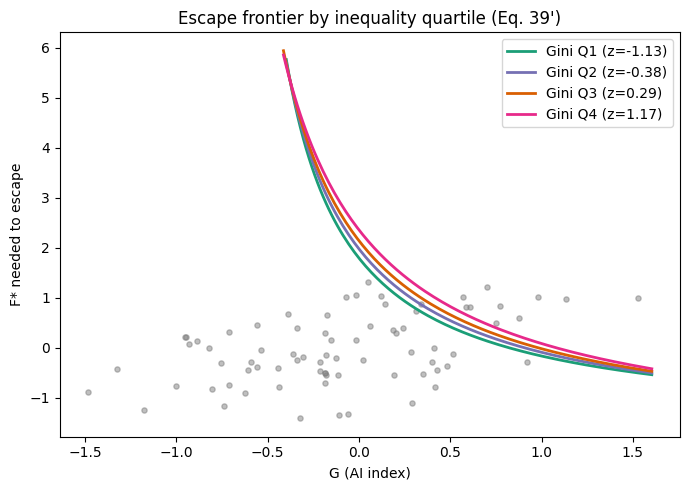

Critical Gini (z-units) where joint-digital denominator vanishes: 9.99


In [ ]:
aFp  = spec1p.params.get("F_l", np.nan)
aGp  = spec1p.params.get("G_l", np.nan)
aFGp = spec1p.params.get("FG_l", np.nan)
eta10 = -spec1p.params.get("Z_gini_l", 0)
eta12 = -spec2p.params.get("FG_Gini_l", 0)
gbar = 2.0
Gg = np.linspace(panel["G"].quantile(.02), panel["G"].quantile(.98), 200)
quarts = panel["Z_gini"].quantile([.125, .375, .625, .875])
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#1b9e77", "#7570b3", "#d95f02", "#e7298a"]
for (q, zq), c in zip(quarts.items(), colors):
    denom = aFp + (aFGp - eta12 * zq) * Gg
    Fs = np.where(np.abs(denom) > 1e-6, (gbar + eta10 * zq - aGp * Gg) / denom, np.nan)
    Fs = np.where((Fs > -4) & (Fs < 6), Fs, np.nan)
    ax.plot(Gg, Fs, color=c, lw=2, label=f"Gini Q{int(q*4+0.5)} (z={zq:.2f})")
mi21 = panel[(panel["year"] == 2021) & (panel["MI"] == 1)].dropna(subset=["F","G"])
ax.scatter(mi21["G"], mi21["F"], s=14, alpha=.5, color="grey")
ax.set_xlabel("G (AI index)"); ax.set_ylabel("F* needed to escape")
ax.set_title("Escape frontier by inequality quartile (Eq. 39')")
ax.legend(); plt.tight_layout(); plt.show()
crit = (aFGp / eta12) if eta12 > 0 else np.nan
print(f"Critical Gini (z-units) where joint-digital denominator vanishes: {crit:.2f}"
      if np.isfinite(crit) else
      "eta12 <= 0 in this sample: no critical Gini (complementarity not eroded)")

### Inequality summary — predicted vs estimated

In [ ]:
rows = []
for label, (specname, par, pred) in INEQ.items():
    res = RESULTS.get(specname)
    if res is None or par not in res.params:
        continue
    b, p = res.params[par], res.pvalues[par]
    ok = (b > 0) if pred == "+" else (b < 0)
    rows.append({"Channel": label, "Spec": specname, "Pred": pred,
                 "Estimate": round(b, 4), "Sig": star(p),
                 "Verdict": ("supported" if ok and p < .10 else
                             "right sign, n.s." if ok else "wrong sign")})
ineq_tab = pd.DataFrame(rows)
print(ineq_tab.to_string(index=False))
print('''
The decisive cells: phi4 (FG x Gini x MI) and beta11 (FG x Gini). If negative,
the earlier finding delta4 ~ 0 is *explained*: joint digital lifts low-Gini
MICs and is extinguished in high-Gini MICs — the "inequality trap embedded in
the digital escape." The tercile test above is the same prediction stated
non-parametrically.''')

                Channel                        Spec Pred  Estimate Sig          Verdict
     beta4 (Gini level)            Spec 1' (Eq.30')    -   -0.2364     right sign, n.s.
      beta10 (G x Gini)            Spec 2' (Eq.31')    -   -1.5509     right sign, n.s.
     beta11 (FG x Gini)            Spec 2' (Eq.31')    -   -0.1176     right sign, n.s.
       beta7 (D x Gini)            Spec 3' (Eq.32')    -   -9.4733     right sign, n.s.
      delta4' (FG x MI)  Spec 4' (Eq.33', headline)    +   -1.0633           wrong sign
            phi1 (Gini)  Spec 4' (Eq.33', headline)    -   -0.6037     right sign, n.s.
  phi4 (FG x Gini x MI)  Spec 4' (Eq.33', headline)    -    0.8018           wrong sign
     gamma1 (G -> Gini) Spec 15 (Eq.49: AI -> Gini)    +    0.0053     right sign, n.s.
gamma2 (G(1-H) -> Gini) Spec 15 (Eq.49: AI -> Gini)    +   -0.0106           wrong sign
  theta (Gini_hat -> g)   Spec 16 (Eq.50: mediated)    - -153.8958     right sign, n.s.
      omega (F x Shock) Spec 18 

## 17. Imputation robustness — headline coefficients, imputed vs complete-case

Re-runs Specs 1 and 4 dropping every observation whose lagged regressors include
any imputed value. If the coefficients move materially, the imputed observations
are doing work they shouldn't — report the complete-case version.

In [ ]:
panel["imp_any_l"] = panel.groupby("iso3")["imp_any"].shift(1)
cc = panel[panel["imp_any_l"] == 0].copy()
s1cc = run_fe("gdp_pc_growth", ["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
              cc, "Spec 1 complete-case")
s4cc = run_fe("gdp_pc_growth",
              ["F_l","G_l","FG_l","MI_l","F_MI_l","G_MI_l","FG_MI_l"]
              + [f"{c}_l" for c in CONTROLS], cc, "Spec 4 complete-case")
comp = pd.DataFrame({
    "imputed panel": [RESULTS["Spec 1 (Eq.30)"].params.get("FG_l", np.nan),
                      RESULTS["Spec 4 (Eq.33, headline)"].params.get("FG_MI_l", np.nan)],
    "complete-case": [s1cc.params.get("FG_l", np.nan),
                      s4cc.params.get("FG_MI_l", np.nan)],
}, index=["beta3 (FxG)", "delta4 (FGxMI)"])
print("\n=== Headline coefficients: imputed vs complete-case ===")
print(comp.round(4).to_string())
print("\nIf the two columns agree, imputation is innocuous: report the imputed "
      "panel with this table in the appendix.")


===== Spec 1 complete-case =====  N=882  countries=130
                                coef      se       t      p
Intercept                   138.8998 24.7801  5.6053 0.0000
F_l                           0.5963  0.7854  0.7593 0.4479
G_l                           2.3228  3.3775  0.6877 0.4918
FG_l                          1.2064  0.7327  1.6466 0.1001
log_gdp_l                   -14.6523  2.6436 -5.5427 0.0000
trade_pct_gdp_l               0.0467  0.0159  2.9326 0.0035
inflation_l                  -0.0358  0.0329 -1.0897 0.2762
investment_pct_gdp_l          0.1018  0.0524  1.9446 0.0522
pop_growth_l                 -0.4576  0.1264 -3.6198 0.0003
credit_to_private_pct_gdp_l  -0.0346  0.0112 -3.0863 0.0021
secondary_enrollment_l        0.0061  0.0172  0.3560 0.7220

===== Spec 4 complete-case =====  N=882  countries=130
                                coef      se       t      p
Intercept                   137.7553 25.1639  5.4743 0.0000
F_l                          -0.1767  1.2116 -0.

MASTER IMPACT SUMMARY

--- 1. Core complementarity ---
                           Finding     Est     SE      p Sig Pred          Verdict
      Joint digital FxG (baseline)  1.0960 0.5230 0.0360  **    +        SUPPORTED
 Joint digital FxG (complete-case)  1.2060 0.7330 0.1000        + right sign, n.s.
Joint digital FxG (mediation spec)  1.5710 0.5340 0.0030 ***    +        SUPPORTED
    Joint digital FxG (dynamic FE)  1.0980 0.5240 0.0360  **    +        SUPPORTED
                      Triple FxGxI -0.0860 0.6500 0.8950        +       wrong sign

--- 2. Threshold ---
                    Finding     Est     SE      p Sig Pred   Verdict
FG below threshold (beta_L) -1.5500 1.1780 0.1890        ?         —
FG above threshold (beta_H)  0.8220 0.4800 0.0870   *    + SUPPORTED

--- 3. Protection ---
                           Finding     Est     SE      p Sig Pred          Verdict
          FinTech -> slowdown risk -0.2660 0.0890 0.0030 ***    -        SUPPORTED
               AI -> slowdown

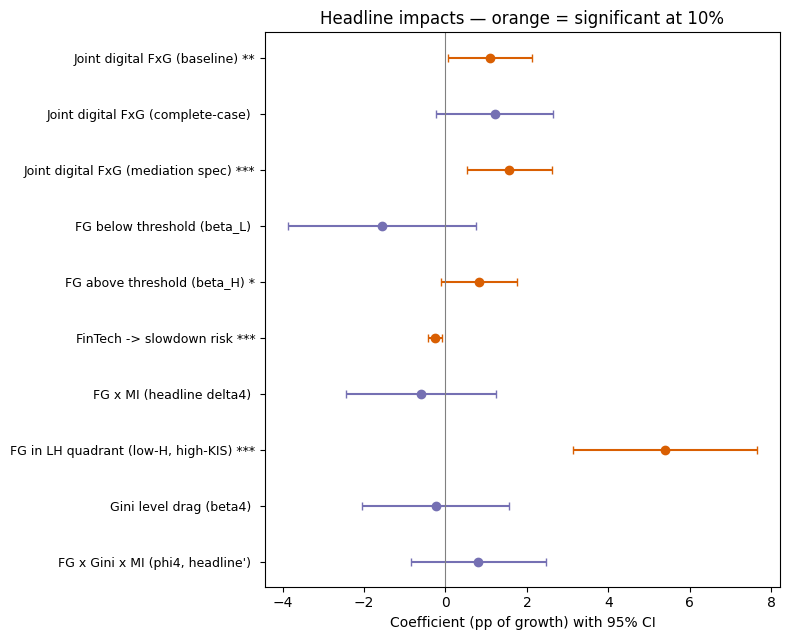

In [ ]:
# ============================================================
#  MASTER IMPACT SUMMARY — every estimated effect in one place
#  (paste as the last cell of the analysis notebook and run)
# ============================================================
def _get(specname, par):
    res = RESULTS.get(specname)
    if res is None or par not in res.params:
        return None
    return (float(res.params[par]), float(res.std_errors[par]), float(res.pvalues[par]))

CATALOG = [
    # (Group, Finding, spec key in RESULTS, parameter, predicted sign)
    ("1. Core complementarity", "Joint digital FxG (baseline)",        "Spec 1 (Eq.30)",                 "FG_l",        "+"),
    ("1. Core complementarity", "Joint digital FxG (complete-case)",   "Spec 1 complete-case",           "FG_l",        "+"),
    ("1. Core complementarity", "Joint digital FxG (mediation spec)",  "Spec 16 (Eq.50: mediated)",      "FG_l",        "+"),
    ("1. Core complementarity", "Joint digital FxG (dynamic FE)",      "Spec 14 (Eq.47, dynamic FE)",    "FG_l",        "+"),
    ("1. Core complementarity", "Triple FxGxI",                        "Spec 2 (Eq.31)",                 "FGI_l",       "+"),
    ("2. Threshold",            "FG below threshold (beta_L)",         "Spec 10 (Eq.40)",                "FG_lo",       "?"),
    ("2. Threshold",            "FG above threshold (beta_H)",         "Spec 10 (Eq.40)",                "FG_hi",       "+"),
    ("3. Protection",           "FinTech -> slowdown risk",            "Spec 5a (Eq.34, LPM-FE)",        "F_l",         "-"),
    ("3. Protection",           "AI -> slowdown risk",                 "Spec 5a (Eq.34, LPM-FE)",        "G_l",         "-"),
    ("3. Protection",           "FinTech x COVID shock (resilience)",  "Spec 18 (Eq.54: resilience)",    "F_Shock",     "+"),
    ("3. Protection",           "Gini x COVID shock",                  "Spec 18 (Eq.54: resilience)",    "Gini_Shock",  "-"),
    ("4. Displacement",         "Displacement drag (per SD)",          "R5 / Spec3 (D z-scored)",        "D_z_l",       "-"),
    ("4. Displacement",         "Displacement x Gini amplifier",       "Spec 3' (Eq.32')",               "D_Gini_l",    "-"),
    ("5. MI heterogeneity",     "FG x MI (headline delta4)",           "Spec 4 (Eq.33, headline)",       "FG_MI_l",     "+"),
    ("5. MI heterogeneity",     "FG in HH quadrant",                   "Spec 8 (Eq.38)",                 "FG_l_HH",     "+"),
    ("5. MI heterogeneity",     "FG in LH quadrant (low-H, high-KIS)", "Spec 8 (Eq.38)",                 "FG_l_LH",     "+"),
    ("5. MI heterogeneity",     "FG in LL quadrant",                   "Spec 8 (Eq.38)",                 "FG_l_LL",     "+"),
    ("6. Inequality channel",   "Gini level drag (beta4)",             "Spec 1' (Eq.30')",               "Z_gini_l",    "-"),
    ("6. Inequality channel",   "G x Gini erosion (beta10)",           "Spec 2' (Eq.31')",               "G_Gini_l",    "-"),
    ("6. Inequality channel",   "FG x Gini erosion (beta11)",          "Spec 2' (Eq.31')",               "FG_Gini_l",   "-"),
    ("6. Inequality channel",   "FG x Gini x MI (phi4, headline')",    "Spec 4' (Eq.33', headline)",     "FG_Gini_MI_l","-"),
    ("6. Inequality channel",   "AI -> Gini first stage (gamma1)",     "Spec 15 (Eq.49: AI -> Gini)",    "G_l",         "+"),
    ("6. Inequality channel",   "Gini_hat -> growth (theta, descr.)",  "Spec 16 (Eq.50: mediated)",      "gini_hat",    "-"),
    ("6. Inequality channel",   "FG: MI bottom-Gini tercile",          "Tercile test (MI sample)",       "FG_l_T1_low", "+"),
    ("6. Inequality channel",   "FG: MI middle-Gini tercile",          "Tercile test (MI sample)",       "FG_l_T2_mid", "+"),
    ("6. Inequality channel",   "FG: MI top-Gini tercile",             "Tercile test (MI sample)",       "FG_l_T3_high","?"),
]

rows = []
for grp, label, spec, par, pred in CATALOG:
    g = _get(spec, par)
    if g is None:
        continue
    b, se, p = g
    if pred == "?":
        verdict = "—"
    else:
        ok = (b > 0) if pred == "+" else (b < 0)
        verdict = ("SUPPORTED" if ok and p < .10 else
                   "right sign, n.s." if ok else "wrong sign")
    rows.append({"Group": grp, "Finding": label, "Est": round(b, 3),
                 "SE": round(se, 3), "p": round(p, 3), "Sig": star(p),
                 "Pred": pred, "Verdict": verdict})
imp = pd.DataFrame(rows)
print("=" * 100)
print("MASTER IMPACT SUMMARY")
print("=" * 100)
for grp, sub in imp.groupby("Group", sort=True):
    print(f"\n--- {grp} ---")
    print(sub.drop(columns="Group").to_string(index=False))

# ---------- derived headline magnitudes ----------
print("\n" + "=" * 100)
print("DERIVED MAGNITUDES (plain-English impacts)")
print("=" * 100)
try:
    b2 = RESULTS["Spec 1 (Eq.30)"].params["G_l"]; b3 = RESULTS["Spec 1 (Eq.30)"].params["FG_l"]
    print(f"* AI dividend dg/dG = {b2:.2f} + {b3:.2f} x F  ->  positive when F > {-b2/b3:.2f} "
          f"(sample F IQR: {panel['F'].quantile(.25):.2f} to {panel['F'].quantile(.75):.2f})")
except Exception: pass
try:
    print(f"* Threshold (Spec 10): joint digital pays only above F*G = {gamma_hat:.3f}; "
          f"slope swings {RESULTS['Spec 10 (Eq.40)'].params['FG_hi'] - RESULTS['Spec 10 (Eq.40)'].params['FG_lo']:+.2f} pp across it")
except Exception: pass
try:
    f_sd = panel["F_l"].std()
    bF = RESULTS["Spec 5a (Eq.34, LPM-FE)"].params["F_l"]
    print(f"* Slowdown protection: +1 SD of F ({f_sd:.2f}) changes slowdown probability by "
          f"{100*bF*f_sd:+.1f} pp (baseline incidence {100*panel['Slowdown'].mean():.0f}%)")
except Exception: pass
try:
    s4p = RESULTS["Spec 4' (Eq.33', headline)"]
    base = s4p.params.get("FG_l", 0) + s4p.params.get("FG_MI_l", 0)
    phi4 = s4p.params.get("FG_Gini_MI_l", 0)
    print(f"* MI joint-digital effect by inequality: {base - phi4:+.2f} (-1 SD Gini) | "
          f"{base:+.2f} (mean) | {base + phi4:+.2f} (+1 SD Gini)")
except Exception: pass
try:
    g1 = RESULTS["Spec 15 (Eq.49: AI -> Gini)"].params["G_l"]
    th = RESULTS["Spec 16 (Eq.50: mediated)"].params["gini_hat"]
    print(f"* Indirect AI-through-inequality channel (descriptive): gamma1 x theta = "
          f"{g1:.4f} x {th:.0f} = {g1*th:+.2f} pp growth per unit G")
except Exception: pass

# ---------- forest plot of the headline coefficients ----------
plot_rows = [r for r in rows if r["Finding"] in {
    "Joint digital FxG (baseline)", "Joint digital FxG (complete-case)",
    "Joint digital FxG (mediation spec)", "FG above threshold (beta_H)",
    "FG below threshold (beta_L)", "FinTech -> slowdown risk",
    "FG in LH quadrant (low-H, high-KIS)", "FG x MI (headline delta4)",
    "FG x Gini x MI (phi4, headline')", "Gini level drag (beta4)"}]
if plot_rows:
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(plot_rows) + 1.5))
    ys = range(len(plot_rows))
    for y, r in zip(ys, plot_rows):
        lo, hi = r["Est"] - 1.96 * r["SE"], r["Est"] + 1.96 * r["SE"]
        sig = r["p"] < 0.10
        ax.errorbar(r["Est"], y, xerr=[[r["Est"] - lo], [hi - r["Est"]]],
                    fmt="o", color="#d95f02" if sig else "#7570b3",
                    capsize=3, markersize=6)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_yticks(list(ys))
    ax.set_yticklabels([f'{r["Finding"]} {r["Sig"]}' for r in plot_rows], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("Coefficient (pp of growth) with 95% CI")
    ax.set_title("Headline impacts — orange = significant at 10%")
    plt.tight_layout(); plt.show()


########################################################################
# Sample A: MI-at-baseline: 110 countries, 1,650 country-years
########################################################################

===== MI-only Spec 1 (A: MI-at-baseline) =====  N=726  countries=70
                                coef      se       t      p
Intercept                   113.9099 25.1864  4.5227 0.0000
F_l                           0.2869  0.8323  0.3448 0.7304
G_l                          -0.5056  3.3622 -0.1504 0.8805
FG_l                          0.6031  0.7242  0.8327 0.4053
log_gdp_l                   -12.1796  2.7604 -4.4122 0.0000
trade_pct_gdp_l               0.0535  0.0168  3.1823 0.0015
inflation_l                  -0.0330  0.0088 -3.7476 0.0002
investment_pct_gdp_l          0.0799  0.0617  1.2959 0.1955
pop_growth_l                 -0.4693  0.2342 -2.0042 0.0455
credit_to_private_pct_gdp_l  -0.0009  0.0203 -0.0460 0.9633
secondary_enrollment_l       -0.0077  0.0210 -0.3667 0.7139



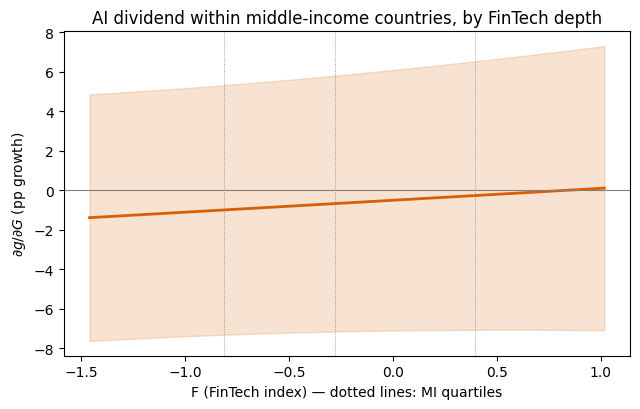

Within MICs: AI dividend = -0.51 + 0.60 x F -> positive when F > 0.84 (MI median F = -0.28)

=== Joint-digital effect: full sample vs middle-income only ===
                 beta3 (FxG)      p
Full sample           1.0960 0.0360
MI-at-baseline        0.6030 0.4050
MI year-varying       0.9810 0.2190


In [ ]:
# ============================================================
#  MIDDLE-INCOME-ONLY ANALYSIS — direct subsample estimation
#  (paste below the Master Impact Summary and run)
# ============================================================
# Sample A (PRIMARY): countries middle-income at baseline, kept throughout.
# Avoids selection-on-success: a country that escapes to H stays in the sample.
first_ig = (panel.dropna(subset=["income_group_hist"])
            .sort_values("year").groupby("iso3")["income_group_hist"].first())
mi_countries = set(first_ig[first_ig.isin(["LM", "UM"])].index)
miA = panel[panel["iso3"].isin(mi_countries)].copy()

# Sample B (ROBUSTNESS): year-varying MI classification (drops graduates on exit)
miB = panel[panel["MI"] == 1].copy()

MI_RES = {}
for name, d in [("A: MI-at-baseline", miA), ("B: MI year-varying", miB)]:
    print(f"\n{'#'*72}\n# Sample {name}: {d['iso3'].nunique()} countries, "
          f"{len(d):,} country-years\n{'#'*72}")

    # --- Spec 1 on the MI subsample ---
    s1 = run_fe("gdp_pc_growth", ["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
                d, f"MI-only Spec 1 ({name})")
    MI_RES[name] = s1

    # --- Spec 5a slowdown protection on the MI subsample ---
    if "Slowdown" in d.columns:
        run_fe("Slowdown", ["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
               d, f"MI-only slowdown LPM ({name})")

# --- Threshold regression on the PRIMARY MI sample (Spec 10 logic) ---
dth = miA.dropna(subset=["gdp_pc_growth","FG_l"] + [f"{c}_l" for c in CONTROLS]).copy()
if len(dth) > 200:
    grid = np.quantile(dth["FG_l"], np.linspace(.15, .85, 30))
    best = (None, np.inf, None)
    for gam in grid:
        dth["FG_lo"] = dth["FG_l"] * (dth["FG_l"] <  gam)
        dth["FG_hi"] = dth["FG_l"] * (dth["FG_l"] >= gam)
        di = dth.set_index(["iso3","year"])
        r = PanelOLS.from_formula(
            "gdp_pc_growth ~ 1 + FG_lo + FG_hi + "
            + " + ".join(f"{c}_l" for c in CONTROLS)
            + " + EntityEffects + TimeEffects", data=di, drop_absorbed=True
        ).fit(cov_type="clustered", cluster_entity=True)
        ssr = float((r.resids**2).sum())
        if ssr < best[1]:
            best = (gam, ssr, r)
    gam_mi, _, r_mi = best
    print(f"\nMI-only threshold: gamma = {gam_mi:.3f} | "
          f"beta_L = {r_mi.params['FG_lo']:.3f}{star(r_mi.pvalues['FG_lo'])}, "
          f"beta_H = {r_mi.params['FG_hi']:.3f}{star(r_mi.pvalues['FG_hi'])}")

# --- Marginal AI effect within MICs (Eq. 15 slice on the MI sample) ---
s1A = MI_RES["A: MI-at-baseline"]
b2, b3 = s1A.params.get("G_l", np.nan), s1A.params.get("FG_l", np.nan)
V = s1A.cov
Fg = np.linspace(miA["F"].quantile(.05), miA["F"].quantile(.95), 60)
me = b2 + b3 * Fg
se = np.sqrt(V.loc["G_l","G_l"] + Fg**2 * V.loc["FG_l","FG_l"] + 2*Fg*V.loc["G_l","FG_l"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(Fg, me, lw=2, color="#d95f02")
ax.fill_between(Fg, me-1.96*se, me+1.96*se, alpha=.18, color="#d95f02")
ax.axhline(0, color="grey", lw=.8)
for q in [.25, .5, .75]:
    ax.axvline(miA["F"].quantile(q), color="grey", lw=.6, ls=":")
ax.set_xlabel("F (FinTech index) — dotted lines: MI quartiles")
ax.set_ylabel(r"$\partial g/\partial G$ (pp growth)")
ax.set_title("AI dividend within middle-income countries, by FinTech depth")
plt.tight_layout(); plt.show()
if b3 != 0:
    print(f"Within MICs: AI dividend = {b2:.2f} + {b3:.2f} x F -> positive when F > {-b2/b3:.2f} "
          f"(MI median F = {miA['F'].median():.2f})")

# --- side-by-side: full sample vs MI-only headline ---
comp = pd.DataFrame({
    "beta3 (FxG)": [RESULTS["Spec 1 (Eq.30)"].params.get("FG_l", np.nan),
                    MI_RES["A: MI-at-baseline"].params.get("FG_l", np.nan),
                    MI_RES["B: MI year-varying"].params.get("FG_l", np.nan)],
    "p": [RESULTS["Spec 1 (Eq.30)"].pvalues.get("FG_l", np.nan),
          MI_RES["A: MI-at-baseline"].pvalues.get("FG_l", np.nan),
          MI_RES["B: MI year-varying"].pvalues.get("FG_l", np.nan)],
}, index=["Full sample", "MI-at-baseline", "MI year-varying"]).round(3)
print("\n=== Joint-digital effect: full sample vs middle-income only ===")
print(comp.to_string())

Manufacturing share fetched: 3,472 rows, 243 countries

Group sizes (countries):
MI_industrial    53
MI_services      52
L_lowincome      35
MI split at manufacturing share = 11.3% of GDP

Example MI_industrial countries: ['ARG', 'BIH', 'BLR', 'BRA', 'CHN', 'CIV', 'CMR', 'COL', 'CRI', 'CUB', 'DOM', 'ECU']
Example MI_services countries:   ['AGO', 'ALB', 'ARM', 'ATG', 'AZE', 'BLZ', 'BOL', 'BTN', 'BWA', 'CHL', 'COG', 'CPV']

===== AI effect by sector-income group =====  N=901  countries=92
                                coef      se       t      p
Intercept                   130.5455 23.0655  5.6598 0.0000
G_l_L_lowincome               6.7929  4.1289  1.6452 0.1003
FG_l_L_lowincome              2.0947  1.2172  1.7209 0.0857
G_l_MI_services               1.2025  5.6341  0.2134 0.8311
FG_l_MI_services             -1.5057  1.8121 -0.8309 0.4063
G_l_MI_industrial            -0.1245  3.1775 -0.0392 0.9687
FG_l_MI_industrial            1.3618  0.7632  1.7842 0.0748
F_l                         

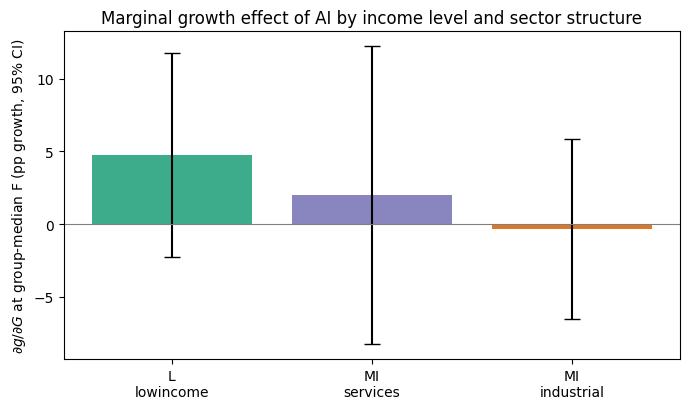


Reading: the 'secondary-sector cooked' hypothesis predicts the orange (MI_industrial) bar lowest — ideally negative — because exposed routine-production structures bear the displacement cost (Eq. 22), while L_lowincome has little exposed employment and MI_services captures the KIS-complementarity (your Spec 8 LH result).


In [ ]:
# ============================================================
#  "WHO GETS COOKED" — AI effect by income level x sector structure
#  Low-income vs MI-services vs MI-industrial (secondary sector)
#  (paste below the MI-only cell and run)
# ============================================================
# --- 1) get manufacturing share of GDP (NV.IND.MANF.ZS) from the WB API ---
import requests
manuf = None
try:
    url = ("https://api.worldbank.org/v2/country/all/indicator/NV.IND.MANF.ZS"
           "?format=json&per_page=20000&date=2010:2024")
    rj = requests.get(url, timeout=60).json()
    rows = [{"iso3": r["countryiso3code"], "year": int(r["date"]),
             "manuf_share": r["value"]}
            for r in rj[1] if r.get("countryiso3code") and r.get("value") is not None]
    manuf = pd.DataFrame(rows)
    manuf = manuf[manuf["iso3"].str.fullmatch(r"[A-Z]{3}")]
    print(f"Manufacturing share fetched: {len(manuf):,} rows, "
          f"{manuf['iso3'].nunique()} countries")
except Exception as e:
    print(f"WB API unavailable ({e}) — falling back to (1 - kis_share) proxy "
          f"for industrial orientation")

if manuf is not None and len(manuf):
    if "manuf_share" in panel.columns:
        panel = panel.drop(columns=["manuf_share"])
    panel = panel.merge(manuf, on=["iso3","year"], how="left")
    panel["industrial_raw"] = panel.groupby("iso3")["manuf_share"].transform("mean")
else:
    panel["industrial_raw"] = 100 * (1 - panel.groupby("iso3")["sigma_kis"].transform("mean"))

# --- 2) define the three structural groups at baseline ---
first_ig = (panel.dropna(subset=["income_group_hist"])
            .sort_values("year").groupby("iso3")["income_group_hist"].first())
grp = pd.Series(index=first_ig.index, dtype="object")
grp[first_ig == "L"] = "L_lowincome"
mi_set = first_ig[first_ig.isin(["LM","UM"])].index
ind_by_c = panel.groupby("iso3")["industrial_raw"].first()
med_manuf = ind_by_c.loc[ind_by_c.index.intersection(mi_set)].median()
grp[[c for c in mi_set if ind_by_c.get(c, np.nan) >= med_manuf]] = "MI_industrial"
grp[[c for c in mi_set if ind_by_c.get(c, np.nan) <  med_manuf]] = "MI_services"
panel["sgroup"] = panel["iso3"].map(grp)
print("\nGroup sizes (countries):")
print(grp.value_counts().to_string())
print(f"MI split at manufacturing share = {med_manuf:.1f}% of GDP")
print("\nExample MI_industrial countries:",
      sorted([c for c in mi_set if grp.get(c)=="MI_industrial"])[:12])
print("Example MI_services countries:  ",
      sorted([c for c in mi_set if grp.get(c)=="MI_services"])[:12])

# --- 3) AI effect by group: G_l and FG_l interacted with group dummies ---
GROUPS = ["L_lowincome", "MI_services", "MI_industrial"]
d3 = panel[panel["sgroup"].isin(GROUPS)].copy()
regs = []
for g in GROUPS:
    for v in ["G_l", "FG_l"]:
        col = f"{v}_{g}"
        d3[col] = d3[v] * (d3["sgroup"] == g)
        regs.append(col)
spec_sector = run_fe("gdp_pc_growth", regs + ["F_l"] + [f"{c}_l" for c in CONTROLS],
                     d3, "AI effect by sector-income group")

# --- 4) displacement drag by group (the 'cooked' channel, Eq. 13/22) ---
for g in GROUPS:
    d3[f"D_z_{g}"] = zscore(d3["D_term"]) * (d3["sgroup"] == g)
    d3[f"D_z_{g}_l"] = d3.groupby("iso3")[f"D_z_{g}"].shift(1)
spec_disp = run_fe("gdp_pc_growth",
                   ["F_l","G_l","FG_l"] + [f"D_z_{g}_l" for g in GROUPS]
                   + [f"{c}_l" for c in CONTROLS],
                   d3, "Displacement drag by group (per SD)")

# --- 5) the headline visual: AI marginal effect per group with 95% CI ---
fig, ax = plt.subplots(figsize=(7, 4.2))
labels, ests, errs, cols = [], [], [], []
palette = {"L_lowincome":"#1b9e77","MI_services":"#7570b3","MI_industrial":"#d95f02"}
for g in GROUPS:
    Fbar = d3.loc[d3["sgroup"]==g, "F_l"].median()
    bG  = spec_sector.params.get(f"G_l_{g}", np.nan)
    bFG = spec_sector.params.get(f"FG_l_{g}", np.nan)
    V = spec_sector.cov
    est = bG + bFG * Fbar
    se = np.sqrt(V.loc[f"G_l_{g}",f"G_l_{g}"] + Fbar**2*V.loc[f"FG_l_{g}",f"FG_l_{g}"]
                 + 2*Fbar*V.loc[f"G_l_{g}",f"FG_l_{g}"])
    labels.append(g.replace("_","\n")); ests.append(est); errs.append(1.96*se)
    cols.append(palette[g])
ax.bar(labels, ests, yerr=errs, capsize=6, color=cols, alpha=.85)
ax.axhline(0, color="grey", lw=.8)
ax.set_ylabel(r"$\partial g/\partial G$ at group-median F (pp growth, 95% CI)")
ax.set_title("Marginal growth effect of AI by income level and sector structure")
plt.tight_layout(); plt.show()

print("\nReading: the 'secondary-sector cooked' hypothesis predicts the orange "
      "(MI_industrial) bar lowest — ideally negative — because exposed routine-"
      "production structures bear the displacement cost (Eq. 22), while "
      "L_lowincome has little exposed employment and MI_services captures the "
      "KIS-complementarity (your Spec 8 LH result).")

Analysis sample: 2020-2024
Countries: 217
Manufacturing share fetched: 1,121 rows, 237 countries

Group sizes (countries):
MI_industrial    53
MI_services      52
L_lowincome      27

MI split at manufacturing share = 12.3%

Example MI_industrial countries: ['ARG', 'BGD', 'BIH', 'BLR', 'CHN', 'CIV', 'CMR', 'COG', 'CRI', 'DOM', 'ECU', 'EGY']
Example MI_services countries: ['AGO', 'ALB', 'ARM', 'AZE', 'BEN', 'BLZ', 'BOL', 'BRA', 'BTN', 'BWA', 'COL', 'CPV']

===== AI effect by sector-income group (2020-2024) =====  N=329  countries=76
                                coef      se       t      p
Intercept                   461.9975 66.8735  6.9085 0.0000
G_l_L_lowincome             -20.5811 24.2638 -0.8482 0.3972
FG_l_L_lowincome              3.6522  7.4083  0.4930 0.6225
G_l_MI_services              16.1210 18.0863  0.8913 0.3737
FG_l_MI_services             -4.3278 12.4148 -0.3486 0.7277
G_l_MI_industrial             5.9826 11.9188  0.5019 0.6162
FG_l_MI_industrial            4.2767  4.74

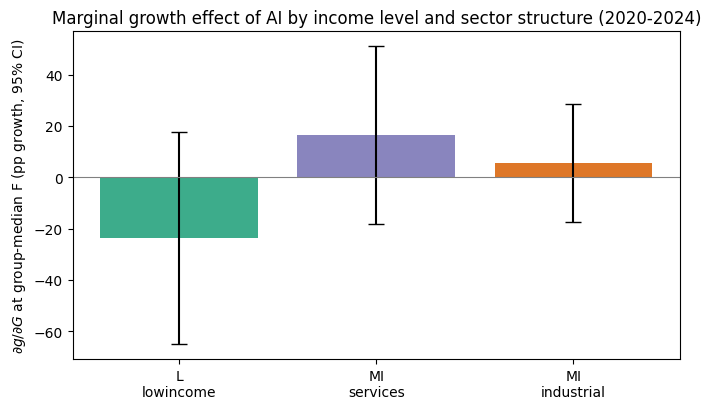


Interpretation:
If the MI_industrial bar is the lowest (especially negative), this supports the 'secondary-sector cooked' hypothesis:
Industrial middle-income economies bear more automation displacement costs.
MI_services should benefit most from AI-KIS complementarity.
Low-income economies should show smaller effects because exposure remains limited.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.structural import UnobservedComponents
from linearmodels.panel import PanelOLS
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    return (s - s.mean()) / s.std()

RESULTS = {}

def run_fe(depvar, regressors, df, name, drop_time_invariant=None):
    """PanelOLS with entity+time effects, country-clustered SEs."""
    cols = [depvar] + regressors
    d = df.dropna(subset=cols).copy()
    # time-invariant-within-country regressors are absorbed by entity FE; drop if requested
    if drop_time_invariant:
        regressors = [r for r in regressors if r not in drop_time_invariant]
    d = d.set_index(["iso3", "year"])
    formula = f"{depvar} ~ 1 + " + " + ".join(regressors) + " + EntityEffects + TimeEffects"
    res = PanelOLS.from_formula(formula, data=d, drop_absorbed=True).fit(
        cov_type="clustered", cluster_entity=True)
    RESULTS[name] = res
    print(f"\n===== {name} =====  N={res.nobs:,}  countries={d.index.get_level_values(0).nunique()}")
    tab = pd.DataFrame({"coef": res.params, "se": res.std_errors,
                        "t": res.tstats, "p": res.pvalues})
    print(tab.round(4).to_string())
    return res


# ============================================================
#  "WHO GETS COOKED" — AI effect by income level x sector structure
#  LOW-INCOME vs MI-SERVICES vs MI-INDUSTRIAL
#  ANALYSIS WINDOW: 2020-2024
# ============================================================

# ------------------------------------------------------------
# Restrict panel to 2020-2024
# ------------------------------------------------------------
panel_2020 = panel[
    (panel["year"] >= 2020) &
    (panel["year"] <= 2024)
].copy()

print(f"Analysis sample: {panel_2020['year'].min()}-{panel_2020['year'].max()}")
print(f"Countries: {panel_2020['iso3'].nunique()}")

# ------------------------------------------------------------
# 1) Manufacturing share of GDP (WB API)
# ------------------------------------------------------------

manuf = None

try:
    url = (
        "https://api.worldbank.org/v2/country/all/"
        "indicator/NV.IND.MANF.ZS"
        "?format=json&per_page=20000&date=2020:2024"
    )

    rj = requests.get(url, timeout=60).json()

    rows = [
        {
            "iso3": r["countryiso3code"],
            "year": int(r["date"]),
            "manuf_share": r["value"]
        }
        for r in rj[1]
        if r.get("countryiso3code")
        and r.get("value") is not None
    ]

    manuf = pd.DataFrame(rows)

    manuf = manuf[
        manuf["iso3"].str.fullmatch(r"[A-Z]{3}")
    ]

    print(
        f"Manufacturing share fetched: "
        f"{len(manuf):,} rows, "
        f"{manuf['iso3'].nunique()} countries"
    )

except Exception as e:

    print(
        f"WB API unavailable ({e}) — "
        f"falling back to (1 - kis_share) proxy"
    )

# ------------------------------------------------------------
# Merge manufacturing data
# ------------------------------------------------------------
if manuf is not None and len(manuf):

    if "manuf_share" in panel_2020.columns:
        panel_2020 = panel_2020.drop(columns=["manuf_share"])

    panel_2020 = panel_2020.merge(
        manuf,
        on=["iso3", "year"],
        how="left"
    )

    panel_2020["industrial_raw"] = (
        panel_2020.groupby("iso3")["manuf_share"]
        .transform("mean")
    )

else:

    panel_2020["industrial_raw"] = (
        100 *
        (
            1 -
            panel_2020.groupby("iso3")["sigma_kis"]
            .transform("mean")
        )
    )

# ------------------------------------------------------------
# 2) Define structural groups
# ------------------------------------------------------------
first_ig = (
    panel_2020
    .dropna(subset=["income_group_hist"])
    .sort_values("year")
    .groupby("iso3")["income_group_hist"]
    .first()
)

grp = pd.Series(
    index=first_ig.index,
    dtype="object"
)

grp[first_ig == "L"] = "L_lowincome"

mi_set = first_ig[
    first_ig.isin(["LM", "UM"])
].index

ind_by_c = (
    panel_2020
    .groupby("iso3")["industrial_raw"]
    .first()
)

med_manuf = (
    ind_by_c.loc[
        ind_by_c.index.intersection(mi_set)
    ]
    .median()
)

grp[
    [
        c for c in mi_set
        if ind_by_c.get(c, np.nan) >= med_manuf
    ]
] = "MI_industrial"

grp[
    [
        c for c in mi_set
        if ind_by_c.get(c, np.nan) < med_manuf
    ]
] = "MI_services"

panel_2020["sgroup"] = (
    panel_2020["iso3"]
    .map(grp)
)

print("\nGroup sizes (countries):")
print(grp.value_counts().to_string())

print(
    f"\nMI split at manufacturing share "
    f"= {med_manuf:.1f}%"
)

print(
    "\nExample MI_industrial countries:",
    sorted(
        [
            c for c in mi_set
            if grp.get(c) == "MI_industrial"
        ]
    )[:12]
)

print(
    "Example MI_services countries:",
    sorted(
        [
            c for c in mi_set
            if grp.get(c) == "MI_services"
        ]
    )[:12]
)

# ------------------------------------------------------------
# 3) AI effect by group
# ------------------------------------------------------------
CONTROLS = ['log_gdp', 'trade_pct_gdp', 'inflation', 'investment_pct_gdp',
            'pop_growth', 'credit_to_private_pct_gdp', 'secondary_enrollment']
GROUPS = [
    "L_lowincome",
    "MI_services",
    "MI_industrial"
]

d3 = panel_2020[
    panel_2020["sgroup"].isin(GROUPS)
].copy()

regs = []

for g in GROUPS:

    for v in ["G_l", "FG_l"]:

        col = f"{v}_{g}"

        d3[col] = (
            d3[v] *
            (d3["sgroup"] == g)
        )

        regs.append(col)

spec_sector = run_fe(
    "gdp_pc_growth",
    regs
    + ["F_l"]
    + [f"{c}_l" for c in CONTROLS],
    d3,
    "AI effect by sector-income group (2020-2024)"
)

print(spec_sector.summary)

# ------------------------------------------------------------
# 4) Displacement drag by group
# ------------------------------------------------------------
for g in GROUPS:

    d3[f"D_z_{g}"] = (
        zscore(d3["D_term"])
        * (d3["sgroup"] == g)
    )

    d3[f"D_z_{g}_l"] = (
        d3.groupby("iso3")[f"D_z_{g}"]
        .shift(1)
    )

spec_disp = run_fe(
    "gdp_pc_growth",
    ["F_l", "G_l", "FG_l"]
    + [f"D_z_{g}_l" for g in GROUPS]
    + [f"{c}_l" for c in CONTROLS],
    d3,
    "Displacement drag by group (2020-2024)"
)

print(spec_disp.summary)

# ------------------------------------------------------------
# 5) Headline plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.2))

labels = []
ests = []
errs = []
cols = []

palette = {
    "L_lowincome": "#1b9e77",
    "MI_services": "#7570b3",
    "MI_industrial": "#d95f02"
}

for g in GROUPS:

    Fbar = d3.loc[
        d3["sgroup"] == g,
        "F_l"
    ].median()

    bG = spec_sector.params.get(
        f"G_l_{g}",
        np.nan
    )

    bFG = spec_sector.params.get(
        f"FG_l_{g}",
        np.nan
    )

    V = spec_sector.cov

    est = bG + bFG * Fbar

    se = np.sqrt(
        V.loc[f"G_l_{g}", f"G_l_{g}"]
        + Fbar**2 *
          V.loc[f"FG_l_{g}", f"FG_l_{g}"]
        + 2 * Fbar *
          V.loc[f"G_l_{g}", f"FG_l_{g}"]
    )

    labels.append(g.replace("_", "\n"))
    ests.append(est)
    errs.append(1.96 * se)
    cols.append(palette[g])

ax.bar(
    labels,
    ests,
    yerr=errs,
    capsize=6,
    color=cols,
    alpha=.85
)

ax.axhline(
    0,
    color="grey",
    lw=.8
)

ax.set_ylabel(
    r"$\partial g/\partial G$ at group-median F "
    "(pp growth, 95% CI)"
)

ax.set_title(
    "Marginal growth effect of AI by income level "
    "and sector structure (2020-2024)"
)

plt.tight_layout()
plt.show()



# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------
print(
    "\nInterpretation:"
    "\nIf the MI_industrial bar is the lowest "
    "(especially negative), this supports the "
    "'secondary-sector cooked' hypothesis:"
    "\nIndustrial middle-income economies bear "
    "more automation displacement costs."
    "\nMI_services should benefit most from "
    "AI-KIS complementarity."
    "\nLow-income economies should show "
    "smaller effects because exposure remains limited."
)

panel.to_csv("final_panel_imputed.csv", index=False)
files.download("final_panel_imputed.csv")


In [ ]:
# ===== AUDIT RESPONSE CELL (hardened, final) — must be the LAST cell =====
# 1) Inflation check (root fix is in Section 0c: inflation removed from IMPUTE_COLS)
if "inflation" in panel.columns:
    cols = ["iso3","year","inflation"] + (["inflation_imp"] if "inflation_imp" in panel.columns else [])
    bad_inf = panel[panel["inflation"] < -30][cols]
    print("Inflation < -30% rows:", "none" if len(bad_inf)==0 else "")
    if len(bad_inf):
        print(bad_inf.to_string(index=False))
        panel.loc[(panel["inflation"] < -30) | (panel["inflation"] > 2000), "inflation"] = np.nan
        panel["inflation_l"] = panel.groupby("iso3")["inflation"].shift(1)
        print("  -> voided and lag rebuilt")

# 2) Sample-stability check (rebuilds any missing lags from base columns)
BASE = ["F","G","FG","Z_gini","G_Gini","FG_Gini","FI","GI","GH","GS","FGI"] + CONTROLS
missing_base = [v for v in BASE if v not in panel.columns]
if missing_base:
    print(f"\nSKIPPED sample-stability check — Sections 1-2 have not run in this "
          f"session (missing: {missing_base[:5]}...). Runtime > Restart and run all.")
else:
    for v in BASE:
        if f"{v}_l" not in panel.columns:
            panel[f"{v}_l"] = panel.groupby("iso3")[v].shift(1)
    common = panel.dropna(subset=["gdp_pc_growth"] + [f"{v}_l" for v in BASE])
    s1_common = run_fe("gdp_pc_growth", ["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS],
                       common, "Spec 1 on common (smallest) sample")
    if "Spec 1 (Eq.30)" in RESULTS:
        print(f"\nbeta3 full sample: {RESULTS['Spec 1 (Eq.30)'].params['FG_l']:.3f} | "
              f"common sample (N={s1_common.nobs}): {s1_common.params['FG_l']:.3f} "
              f"-> if similar, spec differences are NOT sample-driven")

    # 3) VIFs on the actual Spec-1 regressor set
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    X = panel[["F_l","G_l","FG_l"] + [f"{c}_l" for c in CONTROLS]].dropna()
    vifs = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
                     index=X.columns).round(1)
    print("\nVIFs (concern above 10; high values on controls are benign):")
    print(vifs.to_string())


Inflation < -30% rows: none

===== Spec 1 on common (smallest) sample =====  N=1,039  countries=108
                                coef      se       t      p
Intercept                   161.4833 23.4956  6.8729 0.0000
F_l                           0.8610  0.6577  1.3091 0.1908
G_l                           2.0027  3.2060  0.6247 0.5323
FG_l                          1.2667  0.5713  2.2173 0.0268
log_gdp_l                   -16.8961  2.4209 -6.9792 0.0000
trade_pct_gdp_l               0.0491  0.0145  3.3747 0.0008
inflation_l                  -0.0178  0.0235 -0.7558 0.4500
investment_pct_gdp_l          0.1107  0.0535  2.0693 0.0388
pop_growth_l                 -0.7217  0.1926 -3.7479 0.0002
credit_to_private_pct_gdp_l  -0.0147  0.0057 -2.5705 0.0103
secondary_enrollment_l        0.0056  0.0140  0.3966 0.6918

beta3 full sample: 1.096 | common sample (N=1039): 1.267 -> if similar, spec differences are NOT sample-driven

VIFs (concern above 10; high values on controls are benign):
F_l   